# 2026-02-11 ~ 2026-05-11 모터 개폐 시간대와 온도 변화 분석

## 분석 목표

이 노트북은 온실 제어 동작을 하루 24시간 관점에서 해석하기 위한 분석이다.
분석 대상이 되는 데이터는 원시 데이터이다.

주요 질문은 다음과 같다.

- 하루 24시간 중 **몇 시에 모터가 주로 열렸는가**?
- 하루 24시간 중 **몇 시에 모터가 주로 닫혔는가**?
- 같은 시간대에 **내부온도와 외부온도는 어떻게 변했는가**?
- 모터 개폐가 단순히 특정 시각에 반복되는 패턴인지, 온도 변화와 함께 해석해야 하는 패턴인지 확인할 수 있는가?

분석 대상 기간은 기존 분석과 동일하게 `2026-02-11 00:00:00`부터 `2026-05-11 17:00:00`까지다. 센서 timestamp는 UTC로 파싱한 뒤, 사람이 해석하기 쉬운 한국 시간 기준 `Asia/Seoul`로 변환해 0~23시 시간대를 계산한다.

## 0. 분석 방법 요약

### 모터를 열고 닫은 시각 정의

모터 파일에는 `open_rate` 컬럼이 있으며, 이 값은 개폐율을 의미한다. 이 노트북에서는 시간순으로 정렬한 뒤 직전 관측값과 비교해 이벤트를 정의한다.

- `open_rate`가 직전보다 증가하면 `open`, 즉 열린 이벤트로 본다.
- `open_rate`가 직전보다 감소하면 `close`, 즉 닫힌 이벤트로 본다.
- 아주 작은 센서 흔들림을 제거하기 위해 기본 변화량 임계값은 `1.0` percentage point로 둔다.

### 내부온도와 외부온도 정의

센서 파일의 컬럼과 파일명을 기준으로 온도 센서를 구분한다.

- `In_`으로 시작하고 `temp`, `humi` 컬럼이 있으면 내부 온습도 센서로 본다.
- `Out_`으로 시작하고 `temp`, `humi` 컬럼이 있으면 외부 온습도 센서로 본다.

온도 변화는 시간대별 평균/중앙값, 그리고 내부-외부 온도 차이로 요약한다.

In [13]:
from __future__ import annotations

import re
from pathlib import Path
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ANALYSIS_START = "2026-02-11 00:00:00"
ANALYSIS_END = "2026-05-11 17:00:00"
ANALYSIS_TIMEZONE = "Asia/Seoul"
MOTOR_CHANGE_THRESHOLD = 1.0

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    path
    for path in [current, *current.parents]
    if (path / "pipeline_output" / "organized_by_sensor").exists()
)
ORGANIZED_SENSOR_ROOT = PROJECT_ROOT / "pipeline_output" / "organized_by_sensor"
OUTPUT_ROOT = PROJECT_ROOT / "data_inspect" / "output" / "motor_temperature_daily_pattern_260211-260511"
PLOT_ROOT = OUTPUT_ROOT / "plots"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
PLOT_ROOT.mkdir(parents=True, exist_ok=True)

ANALYSIS_START_TS = pd.Timestamp(ANALYSIS_START, tz="UTC")
ANALYSIS_END_TS = pd.Timestamp(ANALYSIS_END, tz="UTC")

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.unicode_minus"] = False

font_candidates = ["AppleGothic", "Malgun Gothic", "NanumGothic", "DejaVu Sans"]
for font_name in font_candidates:
    try:
        plt.rcParams["font.family"] = font_name
        break
    except Exception:
        pass

print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"ORGANIZED_SENSOR_ROOT = {ORGANIZED_SENSOR_ROOT}")
print(f"OUTPUT_ROOT = {OUTPUT_ROOT}")

PROJECT_ROOT = /Users/jeong-won-il/workspace/SDF/train
ORGANIZED_SENSOR_ROOT = /Users/jeong-won-il/workspace/SDF/train/pipeline_output/organized_by_sensor
OUTPUT_ROOT = /Users/jeong-won-il/workspace/SDF/train/data_inspect/output/motor_temperature_daily_pattern_260211-260511


## 1. 센서 데이터 로드

기존 분석과 동일하게 `pipeline_output/organized_by_sensor` 아래의 센서별 CSV를 읽는다.

각 CSV는 다음 기준으로 분류한다.

- `open_rate` 컬럼이 있으면 모터 개폐율 데이터
- `temp`, `humi` 컬럼이 있고 파일명이 `In_`으로 시작하면 내부 환경 데이터
- `temp`, `humi` 컬럼이 있고 파일명이 `Out_`으로 시작하면 외부 환경 데이터

분석 기간 밖의 행은 제외한다.

In [14]:
def parse_datetime_column(series: pd.Series) -> pd.Series:
    try:
        return pd.to_datetime(series, errors="coerce", utc=True, format="mixed")
    except (TypeError, ValueError):
        return pd.to_datetime(series, errors="coerce", utc=True)


def classify_data_kind(path: Path, columns: List[str]) -> str:
    column_set = set(columns)
    if "open_rate" in column_set:
        return "motor_open_rate"
    if {"TEMP(기존SDS경로에있던내용)", "humi"}.issubset(column_set):
        return "internal_environment" if path.name.startswith("In_") else "external_environment"
    return "other"


def short_id(value: object) -> str:
    if pd.isna(value):
        return "none"
    text = str(value).strip()
    return text[:8] if text else "none"


def build_sensor_label(path: Path, frame: pd.DataFrame, data_kind: str) -> str:
    sensor_group = path.parent.name
    sensor_id = "unknown"
    if "sensor_id" in frame.columns and frame["sensor_id"].notna().any():
        sensor_id = short_id(frame["sensor_id"].dropna().iloc[0])

    if data_kind == "motor_open_rate":
        probe = None
        if "probe" in frame.columns and frame["probe"].notna().any():
            probe = str(frame["probe"].dropna().iloc[0])
        if probe is None:
            match = re.search(r"_ch(\d+)_", path.name)
            probe = match.group(1) if match else "unknown"
        return f"{sensor_group} | {sensor_id} | ch{probe}"

    direction = "In" if path.name.startswith("In_") else "Out"
    return f"{sensor_group} | {direction} | {sensor_id}"


def discover_sensor_files(root: Path) -> List[Path]:
    return sorted(
        path
        for path in root.rglob("*.csv")
        if path.name != "organizing_summary.csv" and not path.name.startswith(".")
    )


def load_sensor_frame(path: Path) -> Optional[Dict[str, object]]:
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        print(f"파일 읽기 실패: {path} ({exc})")
        return None

    frame.columns = [str(column).strip() for column in frame.columns]
    if "ts" not in frame.columns:
        return None

    frame["ts"] = parse_datetime_column(frame["ts"])
    frame = frame[frame["ts"].between(ANALYSIS_START_TS, ANALYSIS_END_TS)].copy()
    data_kind = classify_data_kind(path, list(frame.columns))
    sensor_label = build_sensor_label(path, frame, data_kind) if not frame.empty else f"{path.parent.name} | empty"

    frame["local_ts"] = frame["ts"].dt.tz_convert(ANALYSIS_TIMEZONE)
    frame["date"] = frame["local_ts"].dt.date
    frame["hour"] = frame["local_ts"].dt.hour
    frame["source_file"] = str(path.relative_to(PROJECT_ROOT))
    frame["sensor_group"] = path.parent.name
    frame["sensor_label"] = sensor_label
    frame["data_kind"] = data_kind

    return {
        "path": path,
        "relative_path": str(path.relative_to(PROJECT_ROOT)),
        "sensor_group": path.parent.name,
        "sensor_label": sensor_label,
        "data_kind": data_kind,
        "frame": frame,
    }


sensor_files = discover_sensor_files(ORGANIZED_SENSOR_ROOT)
records = [record for path in sensor_files if (record := load_sensor_frame(path)) is not None]

file_overview = pd.DataFrame(
    [
        {
            "sensor_label": record["sensor_label"],
            "data_kind": record["data_kind"],
            "rows": len(record["frame"]),
            "source_file": record["relative_path"],
        }
        for record in records
    ]
)

display(file_overview.groupby("data_kind")["rows"].agg(["count", "sum"]).reset_index())
display(file_overview.head(10))

,data_kind,count,sum
0,external_environment,1,87242
1,internal_environment,2,175663
2,motor_open_rate,16,2344192
3,other,2,174505


,sensor_label,data_kind,rows,source_file
0,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
1,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch2,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
2,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch3,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
3,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch4,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
4,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch5,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
5,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch6,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
6,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch7,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
7,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch8,motor_open_rate,146549,pipeline_output/organized_by_sensor/AGS Green ...
8,AGS Green 단동 7동 온습도 센서 | In | c03b3850,internal_environment,87808,pipeline_output/organized_by_sensor/AGS Green ...
9,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch1,motor_open_rate,146475,pipeline_output/organized_by_sensor/AGS Green ...


## 2. 모터 개폐 이벤트 추출

이 절에서는 각 모터 채널의 `open_rate` 변화를 이벤트로 변환한다.

예를 들어 `open_rate`가 20에서 35로 증가했다면 모터가 더 열린 것으로 보고 `open` 이벤트로 기록한다. 반대로 35에서 10으로 감소했다면 `close` 이벤트로 기록한다.

이 방식은 개폐 명령 자체를 직접 읽는 것이 아니라, 결과 상태값인 개폐율 변화를 이용한 추정이다. 따라서 해석할 때는 “모터가 열린/닫힌 것으로 관측된 시각”으로 이해하는 것이 안전하다.

In [15]:
def build_motor_events(records: List[Dict[str, object]], threshold: float = MOTOR_CHANGE_THRESHOLD) -> pd.DataFrame:
    event_frames = []

    for record in records:
        if record["data_kind"] != "motor_open_rate":
            continue

        frame = record["frame"].copy()
        if frame.empty or "open_rate" not in frame.columns:
            continue

        values = frame[["ts", "local_ts", "date", "hour", "open_rate", "sensor_label", "source_file"]].copy()
        values["open_rate"] = pd.to_numeric(values["open_rate"], errors="coerce")
        values = values.dropna(subset=["ts", "local_ts", "open_rate"]).sort_values("ts")
        values = values.drop_duplicates(subset=["ts"], keep="last")
        values["prev_open_rate"] = values["open_rate"].shift(1)
        values["delta_open_rate"] = values["open_rate"] - values["prev_open_rate"]
        values = values[values["delta_open_rate"].abs() >= threshold].copy()

        if values.empty:
            continue

        values["event_type"] = np.where(values["delta_open_rate"] > 0, "open", "close")
        values["abs_delta_open_rate"] = values["delta_open_rate"].abs()
        event_frames.append(values)

    if not event_frames:
        return pd.DataFrame(
            columns=[
                "ts",
                "local_ts",
                "date",
                "hour",
                "sensor_label",
                "event_type",
                "open_rate",
                "prev_open_rate",
                "delta_open_rate",
                "abs_delta_open_rate",
                "source_file",
            ]
        )

    return pd.concat(event_frames, ignore_index=True).sort_values("local_ts")


motor_events = build_motor_events(records)
motor_events.to_csv(OUTPUT_ROOT / "motor_open_close_events.csv", index=False, encoding="utf-8-sig")

print(f"모터 개폐 이벤트 수: {len(motor_events):,}")
if not motor_events.empty:
    display(motor_events[["local_ts", "sensor_label", "event_type", "prev_open_rate", "open_rate", "delta_open_rate"]].head(20))

모터 개폐 이벤트 수: 2,938


,local_ts,sensor_label,event_type,prev_open_rate,open_rate,delta_open_rate
1021,2026-02-12 10:52:34.438000+09:00,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch4,open,0.0,4,4.0
746,2026-02-12 10:52:34.438000+09:00,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch3,open,0.0,4,4.0
2219,2026-02-12 10:52:34.723000+09:00,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch3,open,0.0,5,5.0
2477,2026-02-12 10:52:34.723000+09:00,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch4,open,0.0,5,5.0
415,2026-02-12 10:53:37.088000+09:00,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch2,open,0.0,30,30.0
747,2026-02-12 10:53:37.088000+09:00,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch3,open,4.0,26,22.0
1022,2026-02-12 10:53:37.088000+09:00,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch4,open,4.0,26,22.0
0,2026-02-12 10:53:37.088000+09:00,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,open,0.0,34,34.0
2220,2026-02-12 10:53:37.372000+09:00,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch3,open,5.0,27,22.0
1524,2026-02-12 10:53:37.372000+09:00,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch1,open,0.0,39,39.0


## 3. 하루 24시간 기준 모터 개폐 시간대

아래 표와 그래프는 0시부터 23시까지 각 시간대에 열린 이벤트와 닫힌 이벤트가 얼마나 많이 발생했는지 보여준다.

해석할 때는 다음을 함께 본다.

- `open` 이벤트가 많은 시간대: 창/환기구가 더 열리는 방향으로 움직인 시간이 많다.
- `close` 이벤트가 많은 시간대: 창/환기구가 더 닫히는 방향으로 움직인 시간이 많다.
- 같은 시간대에 `open`과 `close`가 모두 많다면, 제어가 빈번하게 반복되었거나 채널별 방향이 다르게 나타났을 수 있다.

,hour,event_type,event_count,mean_abs_delta_open_rate,median_abs_delta_open_rate,sensor_count
0,6,close,18,16.888889,18.0,4
1,7,close,26,12.538462,11.0,4
2,7,open,3,1.333333,1.0,2
3,9,close,57,11.368421,6.0,10
4,9,open,360,19.575000,19.0,12
5,10,close,56,11.410714,7.0,8
6,10,open,451,16.538803,13.0,12
7,11,close,57,12.228070,5.0,12
8,11,open,209,12.038278,7.0,12
9,12,close,55,9.054545,3.0,10


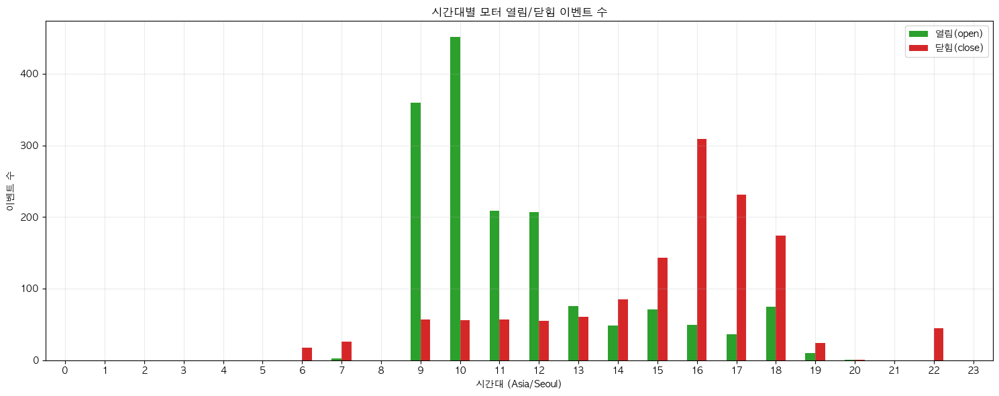

In [16]:
def summarize_motor_events_by_hour(motor_events: pd.DataFrame) -> pd.DataFrame:
    if motor_events.empty:
        return pd.DataFrame(columns=["hour", "event_type", "event_count", "mean_abs_delta_open_rate"])

    summary = (
        motor_events.groupby(["hour", "event_type"])
        .agg(
            event_count=("event_type", "size"),
            mean_abs_delta_open_rate=("abs_delta_open_rate", "mean"),
            median_abs_delta_open_rate=("abs_delta_open_rate", "median"),
            sensor_count=("sensor_label", "nunique"),
        )
        .reset_index()
    )
    return summary.sort_values(["hour", "event_type"])


motor_hour_summary = summarize_motor_events_by_hour(motor_events)
motor_hour_summary.to_csv(OUTPUT_ROOT / "motor_open_close_events_by_hour.csv", index=False, encoding="utf-8-sig")

display(motor_hour_summary)

if not motor_hour_summary.empty:
    pivot = (
        motor_hour_summary.pivot(index="hour", columns="event_type", values="event_count")
        .reindex(range(24))
        .fillna(0)
    )
    for column in ["open", "close"]:
        if column not in pivot.columns:
            pivot[column] = 0
    pivot = pivot[["open", "close"]]

    ax = pivot.plot(kind="bar", figsize=(15, 6), color=["#2ca02c", "#d62728"])
    ax.set_title("시간대별 모터 열림/닫힘 이벤트 수")
    ax.set_xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
    ax.set_ylabel("이벤트 수")
    ax.legend(["열림(open)", "닫힘(close)"])
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / "motor_open_close_events_by_hour.png", dpi=150)
    plt.show()

## 4. 채널별 모터 개폐 시간대 차이

전체 합계만 보면 특정 채널이 압도적으로 많이 움직였는지, 여러 채널이 동시에 비슷한 패턴을 보였는지 구분하기 어렵다.

따라서 채널별·시간대별 이벤트 수를 heatmap 형태로 확인한다. 색이 진한 시간대는 해당 채널에서 개폐 변화가 많이 관측된 시간대다.

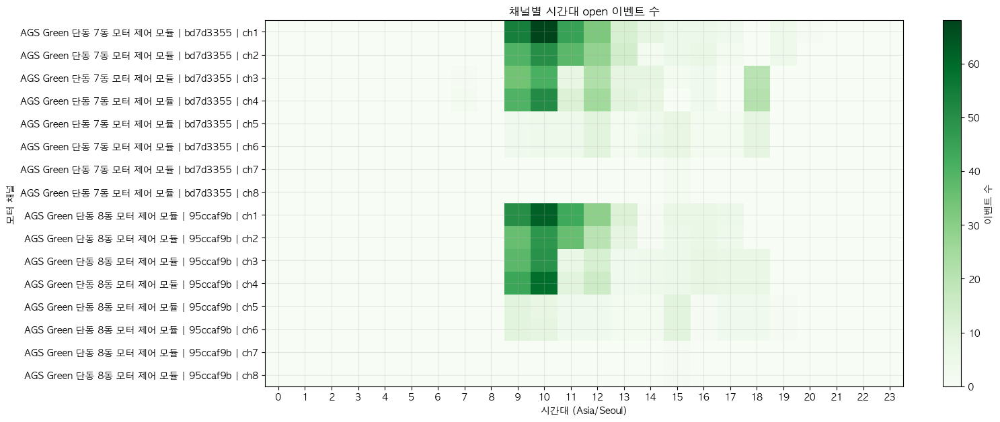

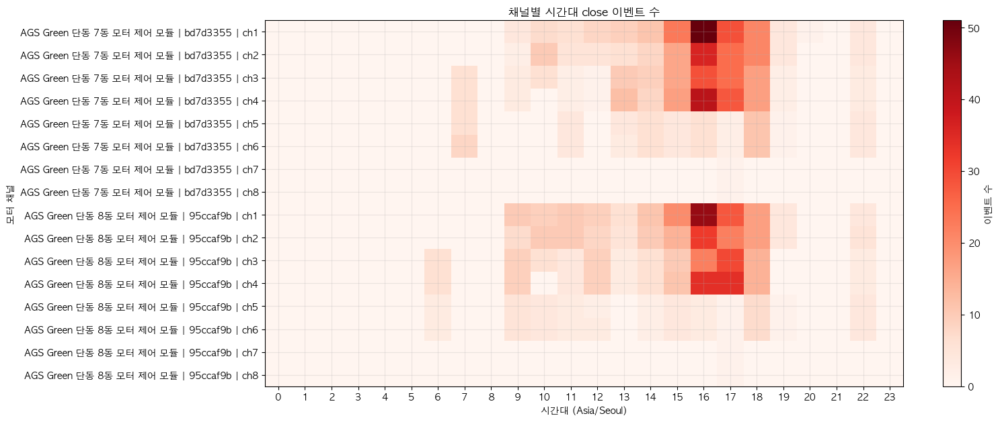

In [17]:
def plot_channel_hour_heatmap(motor_events: pd.DataFrame, event_type: str) -> None:
    subset = motor_events[motor_events["event_type"] == event_type].copy()
    if subset.empty:
        display(Markdown(f"`{event_type}` 이벤트가 없어 heatmap을 그리지 않았다."))
        return

    heatmap_data = (
        subset.groupby(["sensor_label", "hour"])
        .size()
        .unstack("hour", fill_value=0)
        .reindex(columns=range(24), fill_value=0)
    )

    height = max(5, len(heatmap_data) * 0.4)
    plt.figure(figsize=(16, height))
    plt.imshow(heatmap_data.values, aspect="auto", cmap="Greens" if event_type == "open" else "Reds")
    plt.colorbar(label="이벤트 수")
    plt.xticks(range(24), range(24))
    plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
    plt.xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
    plt.ylabel("모터 채널")
    plt.title(f"채널별 시간대 {event_type} 이벤트 수")
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / f"motor_{event_type}_events_channel_hour_heatmap.png", dpi=150)
    plt.show()


plot_channel_hour_heatmap(motor_events, "open")
plot_channel_hour_heatmap(motor_events, "close")

## 5. 내부온도와 외부온도 데이터 구성

이제 온도 센서 데이터를 하나의 긴 테이블로 합친다. 내부온도와 외부온도를 같은 시간축에서 비교하기 위해 1시간 단위 중앙값으로 리샘플링한다.

1시간 단위로 보는 이유는 다음과 같다.

- 원시 센서 주기가 서로 다를 수 있다.
- 개폐 이벤트는 짧은 시간에 발생하지만, 온도 변화는 더 완만하게 나타난다.
- 하루 24시간 패턴을 보려면 과도하게 촘촘한 단위보다 시간대 평균/중앙값이 해석하기 쉽다.

In [18]:
def build_temperature_table(records: List[Dict[str, object]]) -> pd.DataFrame:
    temperature_frames = []

    for record in records:
        data_kind = record["data_kind"]
        if data_kind not in {"internal_environment", "external_environment"}:
            continue

        frame = record["frame"].copy()
        if frame.empty or "TEMP(기존SDS경로에있던내용)" not in frame.columns:
            continue

        values = frame[["ts", "local_ts", "date", "hour", "TEMP(기존SDS경로에있던내용)", "sensor_label", "source_file"]].copy()
        values["TEMP(기존SDS경로에있던내용)"] = pd.to_numeric(values["TEMP(기존SDS경로에있던내용)"], errors="coerce")
        values = values.dropna(subset=["ts", "local_ts", "TEMP(기존SDS경로에있던내용)"])
        values["scope"] = "internal" if data_kind == "internal_environment" else "external"
        temperature_frames.append(values)

    if not temperature_frames:
        return pd.DataFrame(columns=["ts", "local_ts", "date", "hour", "TEMP(기존SDS경로에있던내용)", "scope", "sensor_label", "source_file"])

    return pd.concat(temperature_frames, ignore_index=True).sort_values("local_ts")


def resample_temperature_hourly(temperature_df: pd.DataFrame) -> pd.DataFrame:
    hourly_frames = []
    if temperature_df.empty:
        return pd.DataFrame(columns=["local_ts", "TEMP(기존SDS경로에있던내용)", "scope", "sensor_label"])

    for (scope, sensor_label), group in temperature_df.groupby(["scope", "sensor_label"]):
        series = (
            group.sort_values("local_ts")
            .drop_duplicates(subset=["local_ts"], keep="last")
            .set_index("local_ts")["TEMP(기존SDS경로에있던내용)"]
            .resample("1h")
            .median()
            .dropna()
        )
        hourly_frames.append(
            pd.DataFrame(
                {
                    "local_ts": series.index,
                    "TEMP(기존SDS경로에있던내용)": series.values,
                    "scope": scope,
                    "sensor_label": sensor_label,
                }
            )
        )

    if not hourly_frames:
        return pd.DataFrame(columns=["local_ts", "TEMP(기존SDS경로에있던내용)", "scope", "sensor_label"])

    hourly = pd.concat(hourly_frames, ignore_index=True)
    hourly["date"] = hourly["local_ts"].dt.date
    hourly["hour"] = hourly["local_ts"].dt.hour
    return hourly


temperature_df = build_temperature_table(records)
temperature_hourly = resample_temperature_hourly(temperature_df)

temperature_df.to_csv(OUTPUT_ROOT / "temperature_raw_long.csv", index=False, encoding="utf-8-sig")
temperature_hourly.to_csv(OUTPUT_ROOT / "temperature_hourly_long.csv", index=False, encoding="utf-8-sig")

print(f"온도 원시 행 수: {len(temperature_df):,}")
print(f"1시간 리샘플링 온도 행 수: {len(temperature_hourly):,}")
if not temperature_hourly.empty:
    display(temperature_hourly.groupby("scope")["TEMP(기존SDS경로에있던내용)"].agg(["count", "mean", "median", "min", "max"]).reset_index())
    display(temperature_hourly.head(10))

온도 원시 행 수: 262,905
1시간 리샘플링 온도 행 수: 6,323


,scope,count,mean,median,min,max
0,external,2105,9.813492,9.5,-7.5,33.4
1,internal,4218,15.700652,13.3,-0.3,37.8


,local_ts,temp,scope,sensor_label,date,hour
0,2026-02-11 09:00:00+09:00,1.80,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,9
1,2026-02-11 10:00:00+09:00,3.00,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,10
2,2026-02-11 11:00:00+09:00,5.15,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,11
3,2026-02-11 12:00:00+09:00,6.20,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,12
4,2026-02-11 13:00:00+09:00,6.30,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,13
5,2026-02-11 14:00:00+09:00,6.20,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,14
6,2026-02-11 15:00:00+09:00,6.10,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,15
7,2026-02-11 16:00:00+09:00,6.20,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,16
8,2026-02-11 17:00:00+09:00,4.60,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,17
9,2026-02-11 18:00:00+09:00,2.60,external,AGS Green 우적 센서 - 온습도 | Out | 9043b35d,2026-02-11,18


## 6. 하루 24시간 기준 내부온도와 외부온도 변화

아래 그래프는 기간 전체를 하루 24시간으로 접어 평균적인 일중 온도 곡선을 만든 것이다.

- 선은 시간대별 평균 온도다.
- 음영은 10~90 percentile 범위를 나타내며, 같은 시간대라도 날짜에 따라 온도가 얼마나 달랐는지 보여준다.
- 내부온도와 외부온도의 차이가 커지는 시간대는 온실 내부 제어 또는 일사 영향이 상대적으로 크게 나타날 수 있는 시간대다.

,scope,hour,count,mean,median,p10,p90
0,external,0,87,5.297701,6.050,-2.480,12.420
1,external,1,87,4.623563,5.300,-2.720,11.340
2,external,2,86,4.001744,4.925,-3.300,10.500
3,external,3,86,3.475000,4.175,-3.800,9.850
4,external,4,86,3.229070,4.300,-4.000,9.600
5,external,5,86,3.202326,4.200,-4.350,9.600
6,external,6,87,3.750000,4.800,-4.540,10.800
7,external,7,87,5.709195,6.400,-3.340,13.920
8,external,8,88,8.122159,9.000,-0.930,16.690
9,external,9,88,10.108523,10.100,1.570,19.175


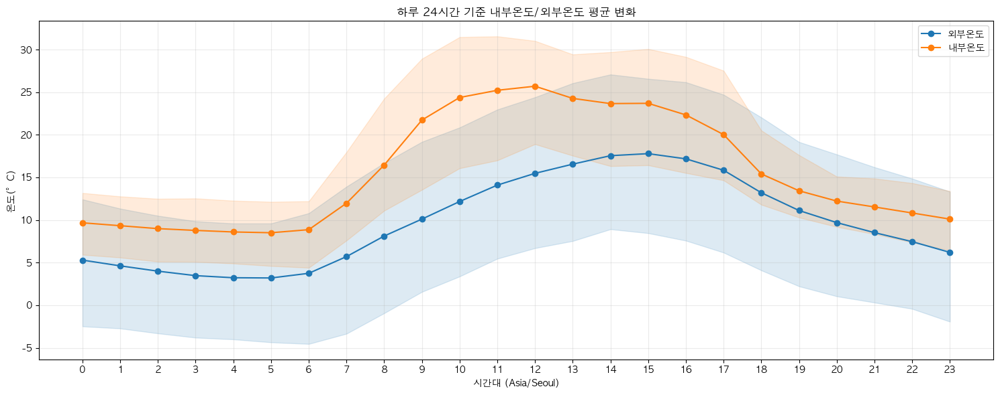

In [19]:
def summarize_temperature_by_hour(temperature_hourly: pd.DataFrame) -> pd.DataFrame:
    if temperature_hourly.empty:
        return pd.DataFrame(columns=["scope", "hour", "count", "mean", "median", "p10", "p90"])

    summary = (
        temperature_hourly.groupby(["scope", "hour"])["TEMP(기존SDS경로에있던내용)"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reset_index()
    )
    return summary.sort_values(["scope", "hour"])


temperature_hour_summary = summarize_temperature_by_hour(temperature_hourly)
temperature_hour_summary.to_csv(OUTPUT_ROOT / "temperature_hourly_profile.csv", index=False, encoding="utf-8-sig")

display(temperature_hour_summary)

if not temperature_hour_summary.empty:
    color_map = {"internal": "#ff7f0e", "external": "#1f77b4"}
    label_map = {"internal": "내부온도", "external": "외부온도"}

    plt.figure(figsize=(15, 6))
    for scope, group in temperature_hour_summary.groupby("scope"):
        group = group.set_index("hour").reindex(range(24)).reset_index()
        x = group["hour"].to_numpy()
        mean = group["mean"].to_numpy(dtype=float)
        p10 = group["p10"].to_numpy(dtype=float)
        p90 = group["p90"].to_numpy(dtype=float)
        color = color_map.get(scope, None)
        plt.plot(x, mean, marker="o", label=label_map.get(scope, scope), color=color)
        plt.fill_between(x, p10, p90, alpha=0.15, color=color)

    plt.title("하루 24시간 기준 내부온도/외부온도 평균 변화")
    plt.xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
    plt.ylabel("온도(°C)")
    plt.xticks(range(24))
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / "temperature_hourly_profile_internal_external.png", dpi=150)
    plt.show()

## 7. 내부-외부 온도 차이

모터 개폐는 절대 온도뿐 아니라 내부온도와 외부온도의 차이에도 영향을 받을 수 있다.

예를 들어 내부온도가 외부보다 높고 낮 시간대 일사 영향이 커지면 환기를 위해 모터가 열릴 가능성이 높다. 반대로 외부가 낮거나 야간에 내부 보온이 필요하면 닫힘 이벤트가 늘어날 수 있다.

아래 분석은 같은 시간대의 내부 평균 온도에서 외부 평균 온도를 뺀 값이다.

,hour,count,mean,median,p10,p90
0,0,87,4.375862,1.3750,-0.8700,12.5600
1,1,87,4.710057,1.3000,-0.4950,12.7300
2,2,86,4.989826,1.6750,-0.2750,12.8625
3,3,86,5.252616,1.9250,0.1375,13.3500
4,4,86,5.342733,1.8250,0.3000,13.5250
5,5,86,5.306395,1.6500,0.3750,13.8500
6,6,87,5.119253,1.9000,-0.6400,13.4300
7,7,87,6.262069,4.8500,1.3550,13.3700
8,8,88,8.330682,7.8250,2.3750,14.2725
9,9,88,11.621023,9.7250,2.9850,21.7775


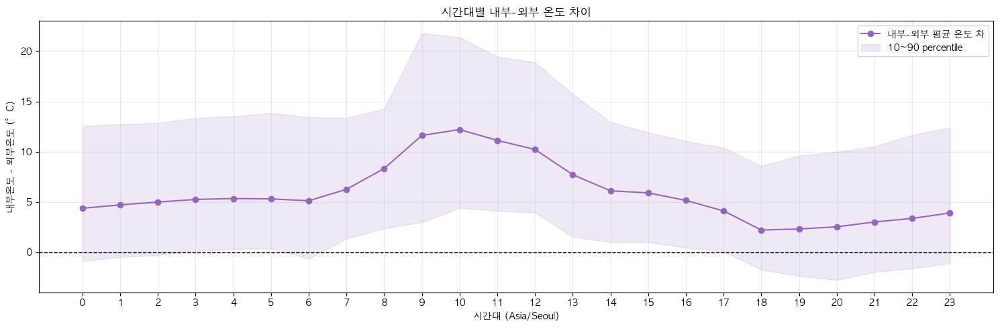

In [20]:
def build_internal_external_gap(temperature_hourly: pd.DataFrame) -> pd.DataFrame:
    if temperature_hourly.empty:
        return pd.DataFrame(columns=["local_ts", "internal", "external", "temp_gap_internal_minus_external", "hour"])

    scope_hourly = (
        temperature_hourly.groupby(["local_ts", "scope"])["TEMP(기존SDS경로에있던내용)"]
        .mean()
        .unstack("scope")
        .sort_index()
    )

    if "internal" not in scope_hourly.columns or "external" not in scope_hourly.columns:
        return pd.DataFrame(columns=["local_ts", "internal", "external", "temp_gap_internal_minus_external", "hour"])

    gap = scope_hourly[["internal", "external"]].dropna().copy()
    gap["temp_gap_internal_minus_external"] = gap["internal"] - gap["external"]
    gap = gap.reset_index()
    gap["hour"] = gap["local_ts"].dt.hour
    gap["date"] = gap["local_ts"].dt.date
    return gap


temperature_gap = build_internal_external_gap(temperature_hourly)
temperature_gap.to_csv(OUTPUT_ROOT / "temperature_internal_external_gap_hourly.csv", index=False, encoding="utf-8-sig")

if temperature_gap.empty:
    display(Markdown("내부온도와 외부온도를 같은 시간대에서 비교할 수 있는 데이터가 부족하다."))
else:
    gap_summary = (
        temperature_gap.groupby("hour")["temp_gap_internal_minus_external"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reindex(range(24))
        .reset_index()
    )
    gap_summary.to_csv(OUTPUT_ROOT / "temperature_internal_external_gap_by_hour.csv", index=False, encoding="utf-8-sig")
    display(gap_summary)

    x = gap_summary["hour"].to_numpy()
    mean = gap_summary["mean"].to_numpy(dtype=float)
    p10 = gap_summary["p10"].to_numpy(dtype=float)
    p90 = gap_summary["p90"].to_numpy(dtype=float)

    plt.figure(figsize=(15, 5))
    plt.plot(x, mean, marker="o", color="#9467bd", label="내부-외부 평균 온도 차")
    plt.fill_between(x, p10, p90, color="#9467bd", alpha=0.15, label="10~90 percentile")
    plt.axhline(0, color="black", linewidth=1, linestyle="--")
    plt.title("시간대별 내부-외부 온도 차이")
    plt.xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
    plt.ylabel("내부온도 - 외부온도 (°C)")
    plt.xticks(range(24))
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / "temperature_internal_external_gap_by_hour.png", dpi=150)
    plt.show()

## 8. 채널별 모터 개폐와 온도 변화를 같은 24시간 축에서 비교

기존 전체 합산 그래프는 모든 모터 채널의 이벤트를 하나로 더해서 보여주기 때문에, 특정 채널이 실제로 어떤 시간대에 열리고 닫혔는지 확인하기 어렵다.

이 절에서는 **모터 채널별로 그래프를 따로 그린다.** 각 그래프는 한 채널에 대해서만 다음 정보를 함께 표시한다.

- 해당 채널의 시간대별 열림 이벤트 수
- 해당 채널의 시간대별 닫힘 이벤트 수
- 전체 내부온도 평균 곡선
- 전체 외부온도 평균 곡선

채널별 그래프를 보면 다음을 구분할 수 있다.

- 특정 채널만 집중적으로 동작하는 시간대가 있는가?
- 같은 시설 안에서도 채널별 열림/닫힘 패턴이 다른가?
- 채널별 개폐 시각이 내부온도 상승 또는 외부온도 변화와 겹치는가?
- 전체 합산 그래프에서 보였던 패턴이 실제로는 일부 채널에 의해 주도된 것인가?

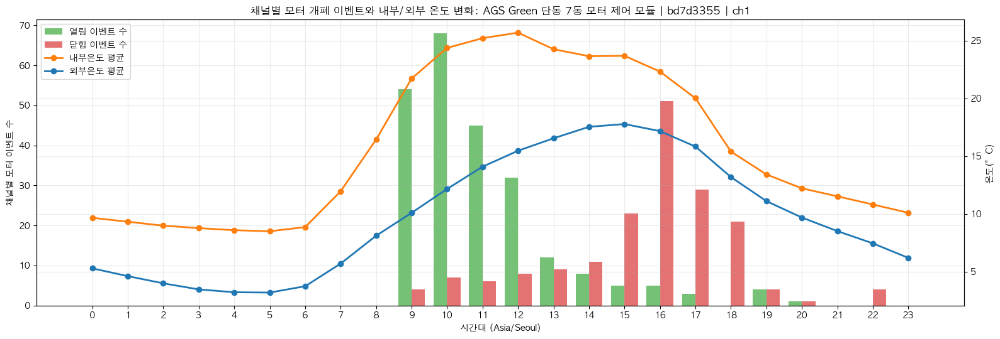

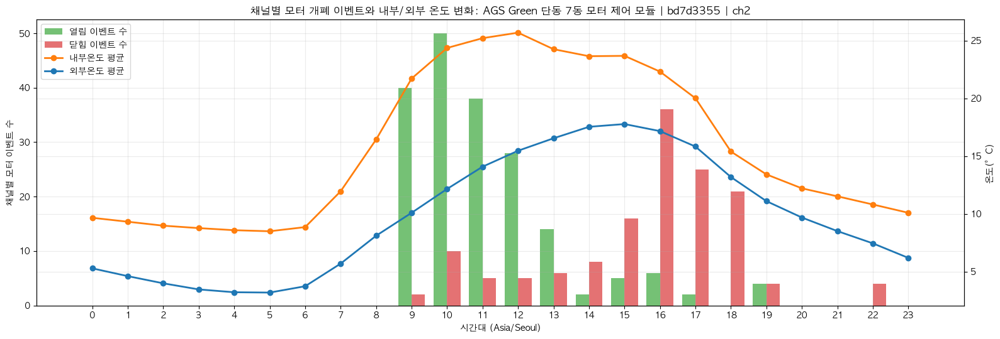

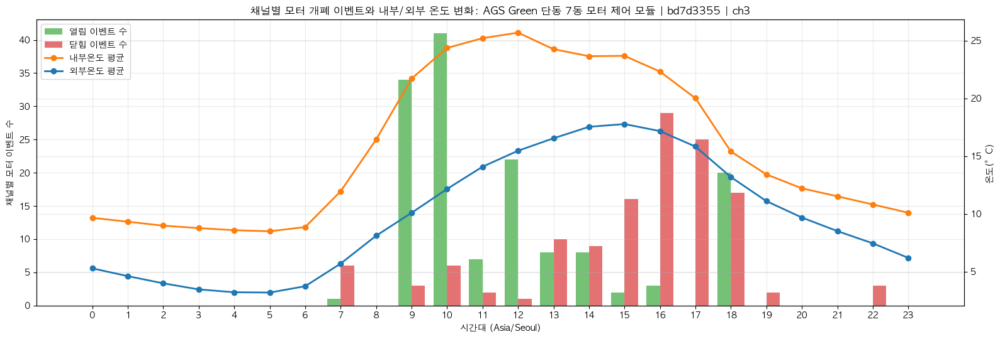

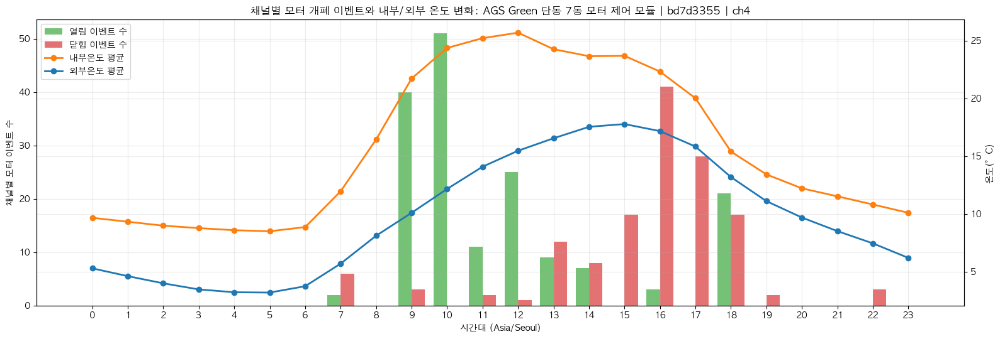

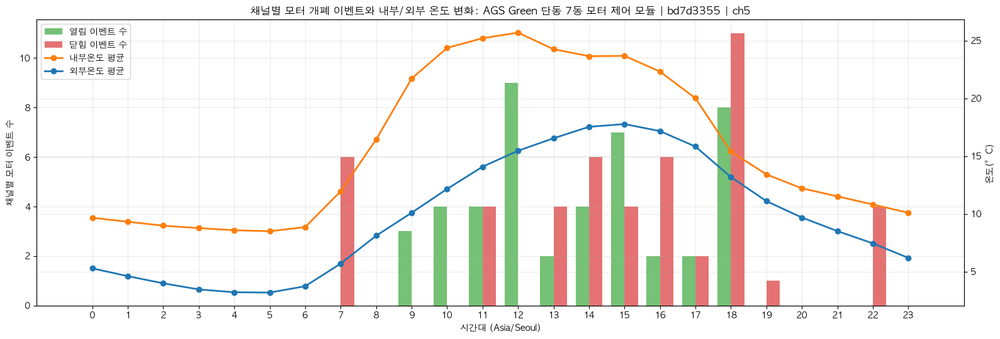

...

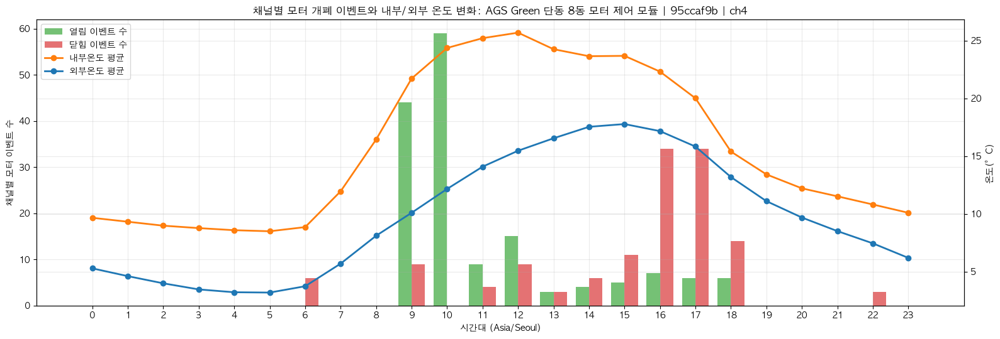

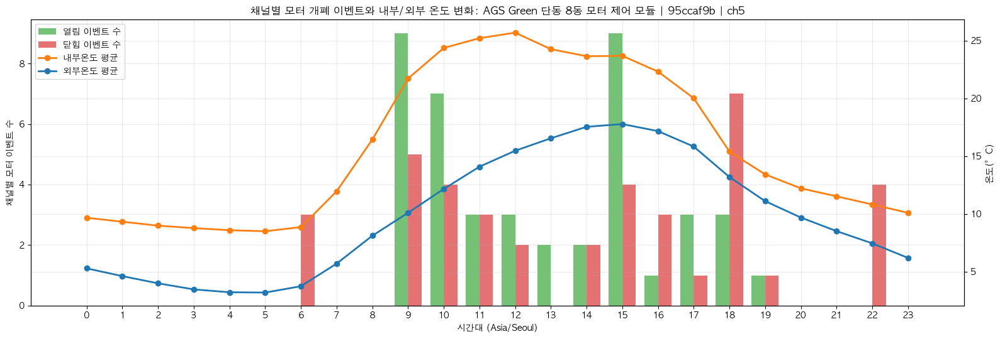

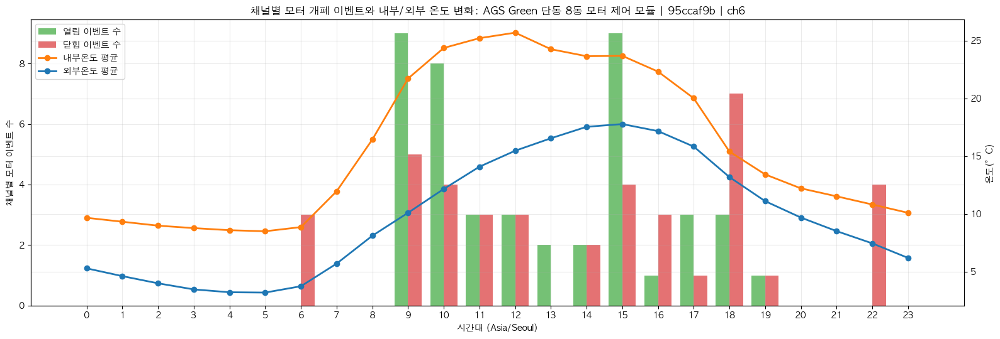

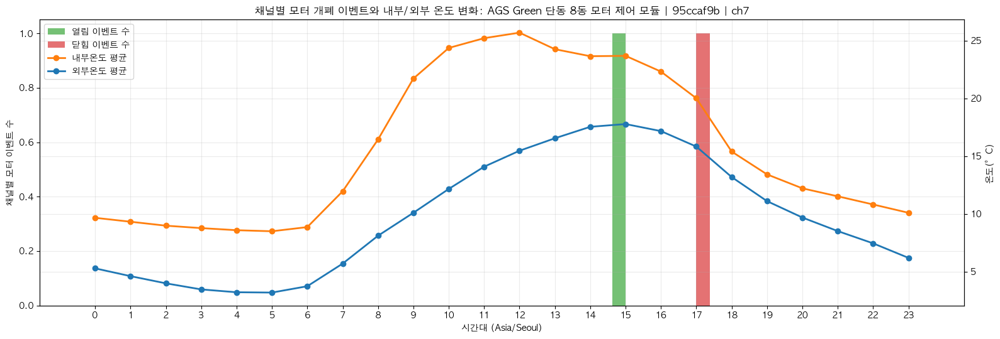

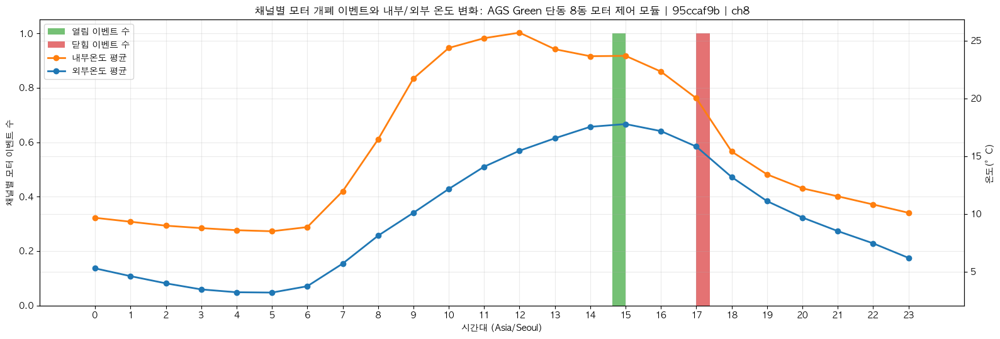

,sensor_label,open_event_count,close_event_count,top_open_hour,top_close_hour
0,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,237,178,10,16
8,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch1,213,174,10,16
1,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch2,189,142,10,16
3,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch4,169,140,10,16
9,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch2,164,144,10,16
11,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch4,158,133,10,16
2,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch3,146,129,10,16
10,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch3,136,122,10,17
5,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch6,46,49,12,18
4,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch5,45,48,12,18


In [21]:
def safe_filename(text: str) -> str:
    safe = re.sub(r"\s+", "_", str(text).strip())
    safe = re.sub(r"[^0-9A-Za-z가-힣_\-]+", "_", safe)
    return re.sub(r"_+", "_", safe).strip("_")[:120]


def build_channel_hour_event_summary(motor_events: pd.DataFrame) -> pd.DataFrame:
    if motor_events.empty:
        return pd.DataFrame(
            columns=[
                "sensor_label",
                "hour",
                "event_type",
                "event_count",
                "mean_abs_delta_open_rate",
                "median_abs_delta_open_rate",
            ]
        )

    return (
        motor_events.groupby(["sensor_label", "hour", "event_type"])
        .agg(
            event_count=("event_type", "size"),
            mean_abs_delta_open_rate=("abs_delta_open_rate", "mean"),
            median_abs_delta_open_rate=("abs_delta_open_rate", "median"),
        )
        .reset_index()
        .sort_values(["sensor_label", "hour", "event_type"])
    )


def build_temperature_pivot_for_overlay(temperature_hour_summary: pd.DataFrame) -> pd.DataFrame:
    if temperature_hour_summary.empty:
        return pd.DataFrame(index=range(24))
    return temperature_hour_summary.pivot(index="hour", columns="scope", values="mean").reindex(range(24))


def plot_channel_motor_temperature_overlay(
    motor_events: pd.DataFrame,
    temperature_hour_summary: pd.DataFrame,
    plot_root: Path,
) -> pd.DataFrame:
    channel_summary = build_channel_hour_event_summary(motor_events)
    channel_summary.to_csv(OUTPUT_ROOT / "motor_open_close_events_by_channel_hour.csv", index=False, encoding="utf-8-sig")

    if motor_events.empty:
        display(Markdown("모터 이벤트가 없어 채널별 통합 그래프를 그리지 않았다."))
        return channel_summary

    temp_pivot = build_temperature_pivot_for_overlay(temperature_hour_summary)
    channel_plot_dir = plot_root / "channel_overlay"
    channel_plot_dir.mkdir(parents=True, exist_ok=True)

    generated_rows = []
    x = np.arange(24)
    width = 0.38

    for sensor_label, channel_events in motor_events.groupby("sensor_label", sort=True):
        event_pivot = (
            channel_events.groupby(["hour", "event_type"])
            .size()
            .unstack("event_type", fill_value=0)
            .reindex(range(24), fill_value=0)
        )
        for column in ["open", "close"]:
            if column not in event_pivot.columns:
                event_pivot[column] = 0
        event_pivot = event_pivot[["open", "close"]]

        top_open_hour = int(event_pivot["open"].idxmax()) if event_pivot["open"].sum() > 0 else np.nan
        top_close_hour = int(event_pivot["close"].idxmax()) if event_pivot["close"].sum() > 0 else np.nan
        generated_rows.append(
            {
                "sensor_label": sensor_label,
                "open_event_count": int(event_pivot["open"].sum()),
                "close_event_count": int(event_pivot["close"].sum()),
                "top_open_hour": top_open_hour,
                "top_close_hour": top_close_hour,
            }
        )

        fig, ax1 = plt.subplots(figsize=(16, 5.5))
        ax1.bar(x - width / 2, event_pivot["open"], width=width, color="#2ca02c", alpha=0.65, label="열림 이벤트 수")
        ax1.bar(x + width / 2, event_pivot["close"], width=width, color="#d62728", alpha=0.65, label="닫힘 이벤트 수")
        ax1.set_xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
        ax1.set_ylabel("채널별 모터 이벤트 수")
        ax1.set_xticks(x)

        ax2 = ax1.twinx()
        if "internal" in temp_pivot.columns:
            ax2.plot(x, temp_pivot["internal"], color="#ff7f0e", marker="o", linewidth=2, label="내부온도 평균")
        if "external" in temp_pivot.columns:
            ax2.plot(x, temp_pivot["external"], color="#1f77b4", marker="o", linewidth=2, label="외부온도 평균")
        ax2.set_ylabel("온도(°C)")

        handles1, labels1 = ax1.get_legend_handles_labels()
        handles2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
        ax1.set_title(f"채널별 모터 개폐 이벤트와 내부/외부 온도 변화: {sensor_label}")
        plt.tight_layout()

        file_path = channel_plot_dir / f"motor_temperature_overlay_{safe_filename(sensor_label)}.png"
        plt.savefig(file_path, dpi=150)
        plt.show()

    channel_top_summary = pd.DataFrame(generated_rows).sort_values(["open_event_count", "close_event_count"], ascending=False)
    channel_top_summary.to_csv(OUTPUT_ROOT / "motor_channel_open_close_peak_hours.csv", index=False, encoding="utf-8-sig")
    display(channel_top_summary)
    return channel_summary


channel_hour_summary = plot_channel_motor_temperature_overlay(motor_events, temperature_hour_summary, PLOT_ROOT)

## 9. 2~5월 월별 모터 개폐 이벤트와 온도 변화 분석

전체 기간을 한 번에 합산하면 2월, 3월, 4월, 5월의 계절 변화가 섞인다. 특히 온실 내부/외부 온도는 월이 바뀌면서 크게 달라질 수 있으므로, 모터 개폐 시간대도 월별로 따로 확인하는 것이 중요하다.

이 절에서는 `2026-02`, `2026-03`, `2026-04`, `2026-05`를 각각 분리해 다음을 계산한다.

- 월별·시간대별 열림/닫힘 이벤트 수
- 월별·시간대별 내부온도/외부온도 평균
- 월별·시간대별 내부-외부 온도 차이
- 월별·채널별 열림/닫힘 이벤트 수와 주요 동작 시간대
- 월별 채널-hour heatmap

월별 그래프를 보면 단순히 “몇 시에 많이 열고 닫는가”뿐 아니라, **계절이 진행되며 같은 시간대의 제어 패턴이 어떻게 달라지는지** 확인할 수 있다.

월별 모터 이벤트 요약


,month,hour,event_type,event_count,mean_abs_delta_open_rate,median_abs_delta_open_rate,sensor_count
0,2026-02,9,close,13,7.153846,8.0,8
1,2026-02,9,open,87,19.758621,15.0,8
2,2026-02,10,close,27,15.777778,13.0,6
3,2026-02,10,open,161,13.186335,10.0,8
4,2026-02,11,close,15,10.600000,5.0,4
...,...,...,...,...,...,...,...
72,2026-05,13,close,4,14.250000,14.0,2
73,2026-05,16,close,2,47.500000,47.5,2
74,2026-05,16,open,2,18.500000,18.5,2
75,2026-05,18,close,16,21.437500,22.0,4


월별 온도 요약


,month,scope,hour,count,mean,median,p10,p90
0,2026-02,external,0,17,-1.138235,-1.600,-4.76,4.04
1,2026-02,external,1,17,-1.802941,-1.600,-5.20,1.73
2,2026-02,external,2,17,-2.052941,-1.900,-5.50,0.82
3,2026-02,external,3,17,-2.500000,-2.900,-6.10,1.10
4,2026-02,external,4,17,-2.597059,-3.100,-6.71,1.88
...,...,...,...,...,...,...,...,...
187,2026-05,internal,19,22,16.281818,16.125,13.43,18.79
188,2026-05,internal,20,22,14.459091,14.325,12.60,17.77
189,2026-05,internal,21,22,13.306818,13.050,10.32,17.27
190,2026-05,internal,22,22,12.490909,12.150,9.46,16.35


월별 채널별 peak 요약


,month,sensor_label,open_event_count,close_event_count,top_open_hour,top_close_hour
0,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,96,80,10.0,16.0
1,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch2,60,52,11.0,16.0
2,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch3,38,33,10.0,16.0
3,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch4,60,43,10.0,16.0
4,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch5,2,3,15.0,17.0
5,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch6,2,3,15.0,17.0
6,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch7,1,1,15.0,17.0
7,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch8,1,1,15.0,17.0
8,2026-02,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch1,83,74,11.0,16.0
9,2026-02,AGS Green 단동 8동 모터 제어 모듈 | 95ccaf9b | ch2,46,48,11.0,16.0


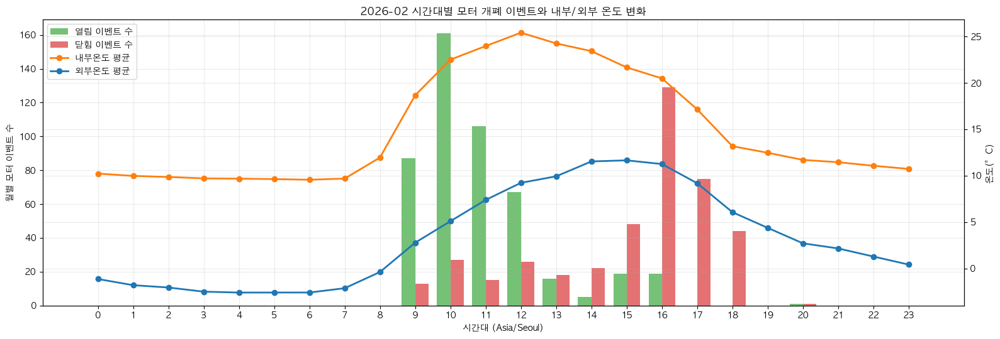

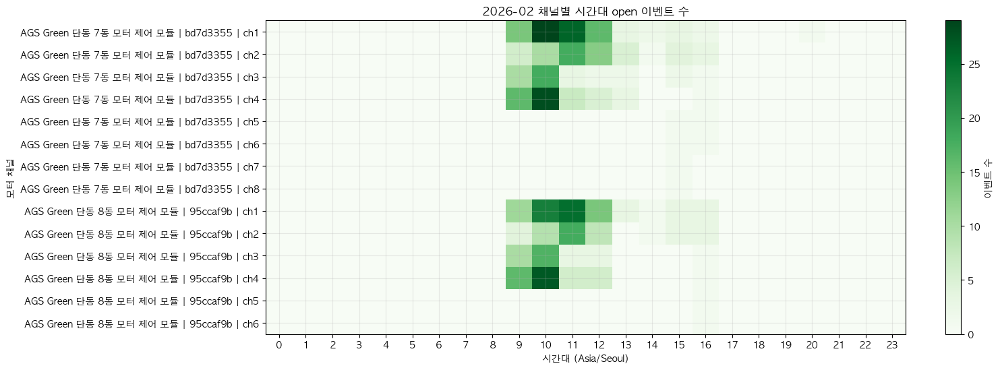

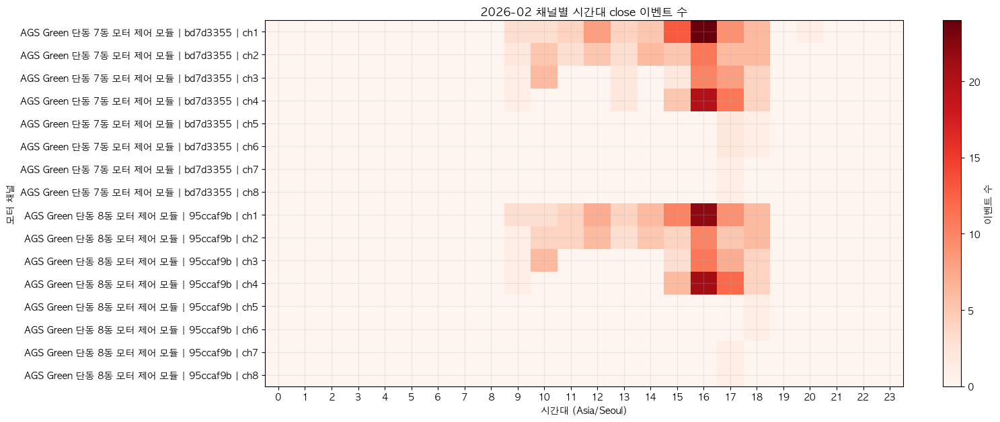

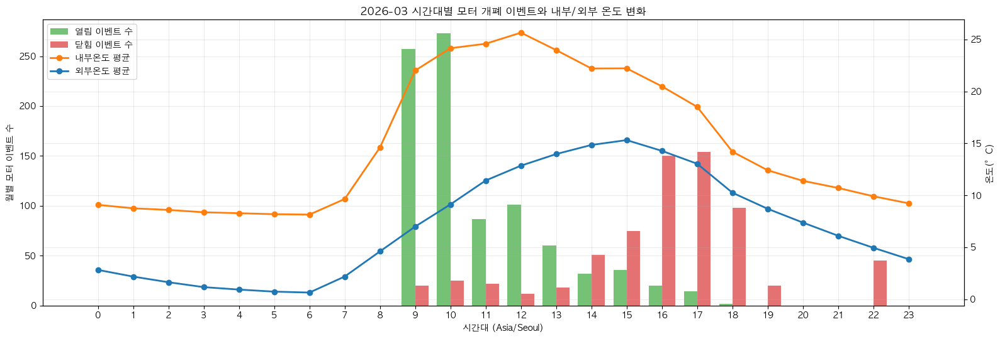

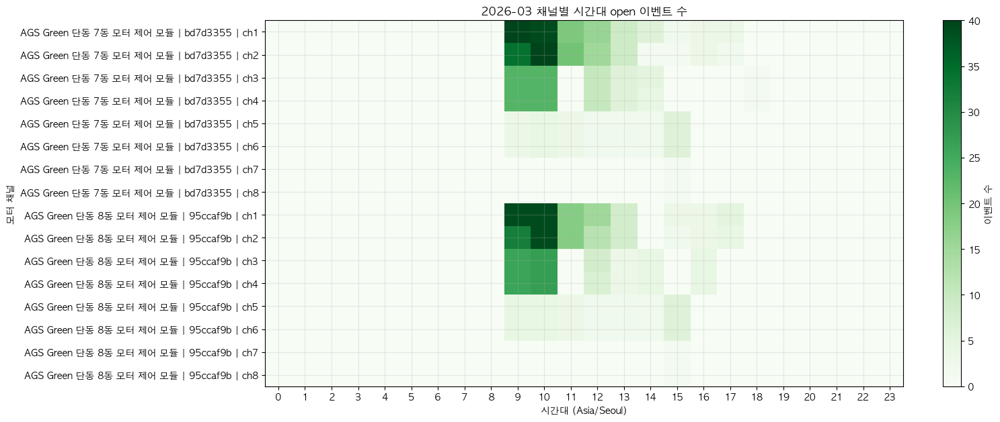

...

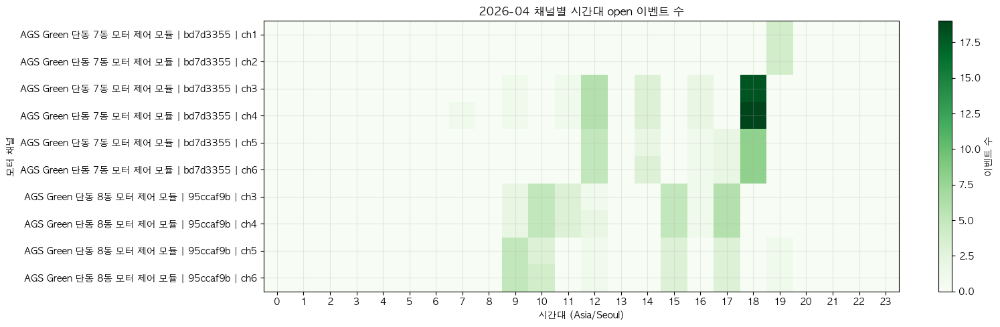

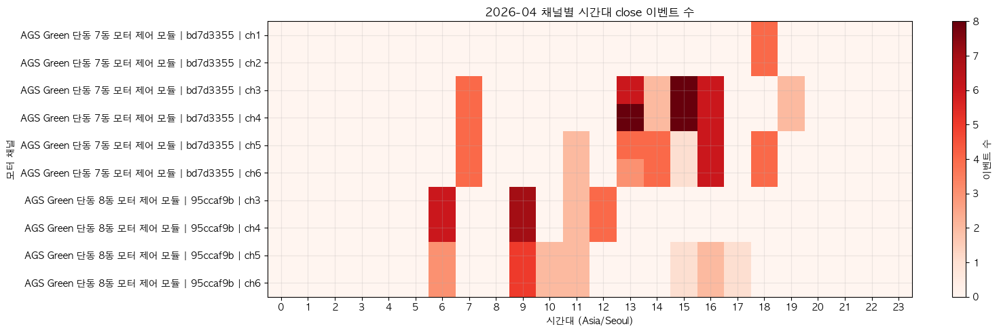

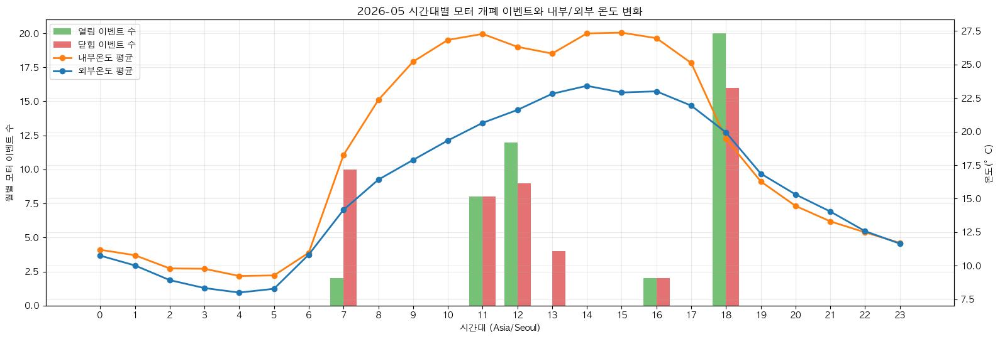

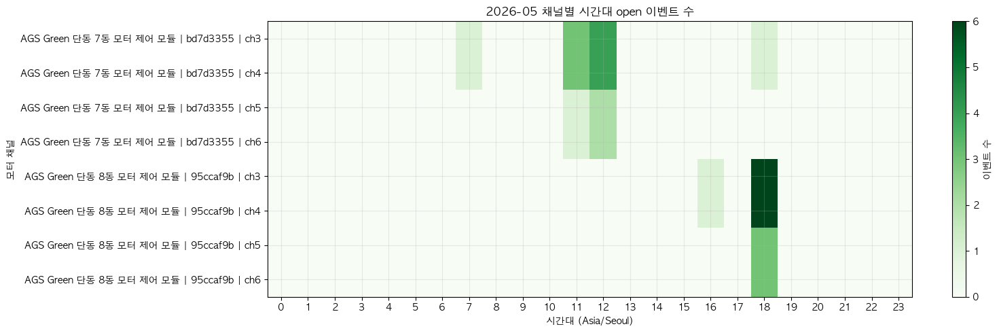

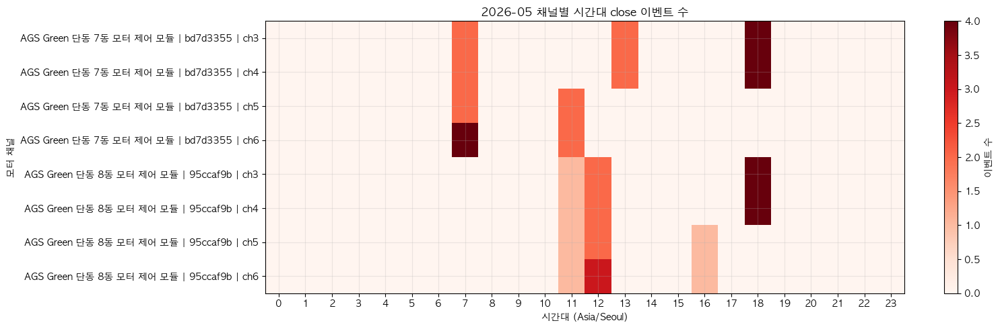

In [22]:
MONTH_ORDER = ["2026-02", "2026-03", "2026-04", "2026-05"]


def add_month_column(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    if "local_ts" in result.columns:
        result["month"] = result["local_ts"].dt.strftime("%Y-%m")
    return result


motor_events_monthly = add_month_column(motor_events)
temperature_hourly_monthly = add_month_column(temperature_hourly)
temperature_gap_monthly = add_month_column(temperature_gap) if "temperature_gap" in globals() else pd.DataFrame()

monthly_motor_summary = pd.DataFrame()
if not motor_events_monthly.empty:
    monthly_motor_summary = (
        motor_events_monthly[motor_events_monthly["month"].isin(MONTH_ORDER)]
        .groupby(["month", "hour", "event_type"])
        .agg(
            event_count=("event_type", "size"),
            mean_abs_delta_open_rate=("abs_delta_open_rate", "mean"),
            median_abs_delta_open_rate=("abs_delta_open_rate", "median"),
            sensor_count=("sensor_label", "nunique"),
        )
        .reset_index()
        .sort_values(["month", "hour", "event_type"])
    )
monthly_motor_summary.to_csv(OUTPUT_ROOT / "monthly_motor_open_close_events_by_hour.csv", index=False, encoding="utf-8-sig")

monthly_channel_event_summary = pd.DataFrame()
if not motor_events_monthly.empty:
    monthly_channel_event_summary = (
        motor_events_monthly[motor_events_monthly["month"].isin(MONTH_ORDER)]
        .groupby(["month", "sensor_label", "hour", "event_type"])
        .agg(
            event_count=("event_type", "size"),
            mean_abs_delta_open_rate=("abs_delta_open_rate", "mean"),
            median_abs_delta_open_rate=("abs_delta_open_rate", "median"),
        )
        .reset_index()
        .sort_values(["month", "sensor_label", "hour", "event_type"])
    )
monthly_channel_event_summary.to_csv(OUTPUT_ROOT / "monthly_motor_open_close_events_by_channel_hour.csv", index=False, encoding="utf-8-sig")

monthly_temperature_summary = pd.DataFrame()
if not temperature_hourly_monthly.empty:
    monthly_temperature_summary = (
        temperature_hourly_monthly[temperature_hourly_monthly["month"].isin(MONTH_ORDER)]
        .groupby(["month", "scope", "hour"])["TEMP(기존SDS경로에있던내용)"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reset_index()
        .sort_values(["month", "scope", "hour"])
    )
monthly_temperature_summary.to_csv(OUTPUT_ROOT / "monthly_temperature_hourly_profile.csv", index=False, encoding="utf-8-sig")

monthly_gap_summary = pd.DataFrame()
if not temperature_gap_monthly.empty:
    monthly_gap_summary = (
        temperature_gap_monthly[temperature_gap_monthly["month"].isin(MONTH_ORDER)]
        .groupby(["month", "hour"])["temp_gap_internal_minus_external"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reset_index()
        .sort_values(["month", "hour"])
    )
monthly_gap_summary.to_csv(OUTPUT_ROOT / "monthly_temperature_internal_external_gap_by_hour.csv", index=False, encoding="utf-8-sig")

monthly_channel_peak_summary = pd.DataFrame()
if not monthly_channel_event_summary.empty:
    monthly_channel_peak_rows = []
    for (month, sensor_label), group in monthly_channel_event_summary.groupby(["month", "sensor_label"]):
        event_pivot = group.pivot_table(index="hour", columns="event_type", values="event_count", aggfunc="sum").reindex(range(24)).fillna(0)
        for column in ["open", "close"]:
            if column not in event_pivot.columns:
                event_pivot[column] = 0
        monthly_channel_peak_rows.append(
            {
                "month": month,
                "sensor_label": sensor_label,
                "open_event_count": int(event_pivot["open"].sum()),
                "close_event_count": int(event_pivot["close"].sum()),
                "top_open_hour": int(event_pivot["open"].idxmax()) if event_pivot["open"].sum() > 0 else np.nan,
                "top_close_hour": int(event_pivot["close"].idxmax()) if event_pivot["close"].sum() > 0 else np.nan,
            }
        )
    monthly_channel_peak_summary = pd.DataFrame(monthly_channel_peak_rows).sort_values(["month", "sensor_label"])
monthly_channel_peak_summary.to_csv(OUTPUT_ROOT / "monthly_motor_channel_open_close_peak_hours.csv", index=False, encoding="utf-8-sig")

print("월별 모터 이벤트 요약")
display(monthly_motor_summary)
print("월별 온도 요약")
display(monthly_temperature_summary)
print("월별 채널별 peak 요약")
display(monthly_channel_peak_summary.head(40))


def plot_monthly_motor_temperature_overlay(month: str) -> None:
    month_events = monthly_motor_summary[monthly_motor_summary["month"] == month]
    month_temp = monthly_temperature_summary[monthly_temperature_summary["month"] == month]

    if month_events.empty and month_temp.empty:
        display(Markdown(f"`{month}`에는 표시할 모터 이벤트/온도 데이터가 없다."))
        return

    event_pivot = month_events.pivot_table(index="hour", columns="event_type", values="event_count", aggfunc="sum").reindex(range(24)).fillna(0)
    for column in ["open", "close"]:
        if column not in event_pivot.columns:
            event_pivot[column] = 0

    temp_pivot = month_temp.pivot(index="hour", columns="scope", values="mean").reindex(range(24)) if not month_temp.empty else pd.DataFrame(index=range(24))

    fig, ax1 = plt.subplots(figsize=(16, 5.5))
    x = np.arange(24)
    width = 0.38
    ax1.bar(x - width / 2, event_pivot["open"], width=width, color="#2ca02c", alpha=0.65, label="열림 이벤트 수")
    ax1.bar(x + width / 2, event_pivot["close"], width=width, color="#d62728", alpha=0.65, label="닫힘 이벤트 수")
    ax1.set_xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
    ax1.set_ylabel("월별 모터 이벤트 수")
    ax1.set_xticks(x)

    ax2 = ax1.twinx()
    if "internal" in temp_pivot.columns:
        ax2.plot(x, temp_pivot["internal"], color="#ff7f0e", marker="o", linewidth=2, label="내부온도 평균")
    if "external" in temp_pivot.columns:
        ax2.plot(x, temp_pivot["external"], color="#1f77b4", marker="o", linewidth=2, label="외부온도 평균")
    ax2.set_ylabel("온도(°C)")

    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
    ax1.set_title(f"{month} 시간대별 모터 개폐 이벤트와 내부/외부 온도 변화")
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / f"monthly_motor_temperature_overlay_{month.replace('-', '_')}.png", dpi=150)
    plt.show()


def plot_monthly_channel_hour_heatmap(month: str, event_type: str) -> None:
    subset = motor_events_monthly[
        (motor_events_monthly["month"] == month) & (motor_events_monthly["event_type"] == event_type)
    ].copy()
    if subset.empty:
        display(Markdown(f"`{month}` `{event_type}` 이벤트가 없어 월별 채널 heatmap을 그리지 않았다."))
        return

    heatmap_data = (
        subset.groupby(["sensor_label", "hour"])
        .size()
        .unstack("hour", fill_value=0)
        .reindex(columns=range(24), fill_value=0)
    )

    height = max(5, len(heatmap_data) * 0.4)
    plt.figure(figsize=(16, height))
    plt.imshow(heatmap_data.values, aspect="auto", cmap="Greens" if event_type == "open" else "Reds")
    plt.colorbar(label="이벤트 수")
    plt.xticks(range(24), range(24))
    plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
    plt.xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
    plt.ylabel("모터 채널")
    plt.title(f"{month} 채널별 시간대 {event_type} 이벤트 수")
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / f"monthly_motor_{event_type}_channel_hour_heatmap_{month.replace('-', '_')}.png", dpi=150)
    plt.show()


for month in MONTH_ORDER:
    plot_monthly_motor_temperature_overlay(month)
    plot_monthly_channel_hour_heatmap(month, "open")
    plot_monthly_channel_hour_heatmap(month, "close")

## 10. 실제 개폐율 값 변화와 계절별 온도 변화 비교

앞의 heatmap과 이벤트 그래프는 “개폐율이 변한 횟수”를 보여준다. 하지만 이벤트 수만으로는 실제 개폐율이 어느 정도 열려 있었는지 알기 어렵다.

이 절에서는 `open_rate`의 실제 값을 1시간 단위로 리샘플링해, 월별·채널별 평균 개폐율 곡선을 그린다. 같은 그래프에 월별 내부온도와 외부온도 평균도 함께 표시한다.

해석 관점은 다음과 같다.

- 이벤트 수가 많지 않아도 평균 개폐율이 높으면, 해당 시간대에는 모터가 이미 열린 상태로 오래 유지되었을 수 있다.
- 이벤트 수가 많지만 평균 개폐율이 낮으면, 짧은 제어 변화가 반복되었을 수 있다.
- 월별 온도 곡선과 평균 개폐율 곡선을 같이 보면, 계절이 따뜻해질수록 같은 시간대의 개방 정도가 커지는지 확인할 수 있다.
- 채널별 개폐율 곡선을 보면 특정 채널이 다른 채널보다 더 많이 열려 있는지, 또는 특정 월에만 다르게 동작하는지 확인할 수 있다.

1시간 리샘플링 개폐율 행 수: 33,888


,month,hour,count,mean,median,p10,p90
0,2026-02,0,272,11.227941,0.0,0.0,95.0
1,2026-02,1,272,11.227941,0.0,0.0,95.0
2,2026-02,2,272,11.227941,0.0,0.0,95.0
3,2026-02,3,256,11.929688,0.0,0.0,95.0
4,2026-02,4,256,10.441406,0.0,0.0,95.0
...,...,...,...,...,...,...,...
91,2026-05,19,176,90.767045,100.0,76.0,100.0
92,2026-05,20,176,90.767045,100.0,76.0,100.0
93,2026-05,21,176,90.767045,100.0,76.0,100.0
94,2026-05,22,176,90.767045,100.0,76.0,100.0


,month,sensor_label,hour,count,mean,median,p10,p90
0,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,0,17,0.000000,0.0,0.0,0.0
1,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,1,17,0.000000,0.0,0.0,0.0
2,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,2,17,0.000000,0.0,0.0,0.0
3,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,3,16,0.000000,0.0,0.0,0.0
4,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,4,16,0.000000,0.0,0.0,0.0
5,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,5,17,0.000000,0.0,0.0,0.0
6,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,6,17,0.000000,0.0,0.0,0.0
7,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,7,17,0.000000,0.0,0.0,0.0
8,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,8,16,0.000000,0.0,0.0,0.0
9,2026-02,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,9,18,3.277778,0.0,0.0,0.0


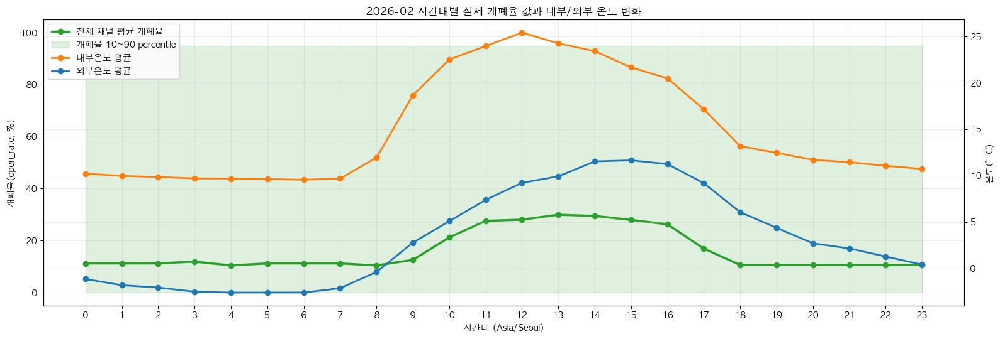

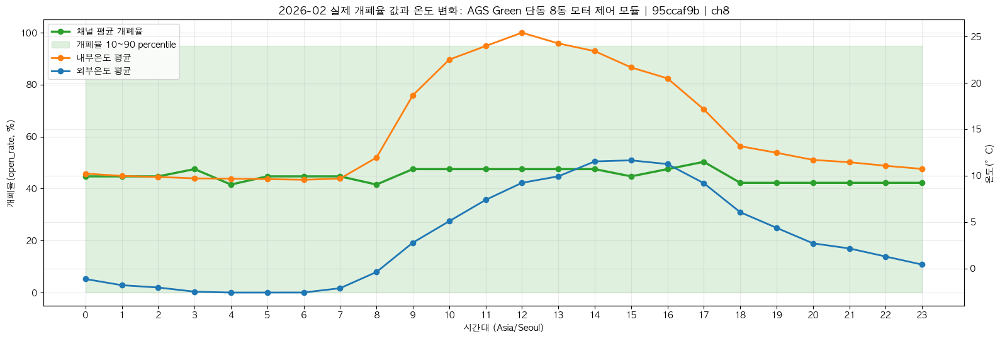

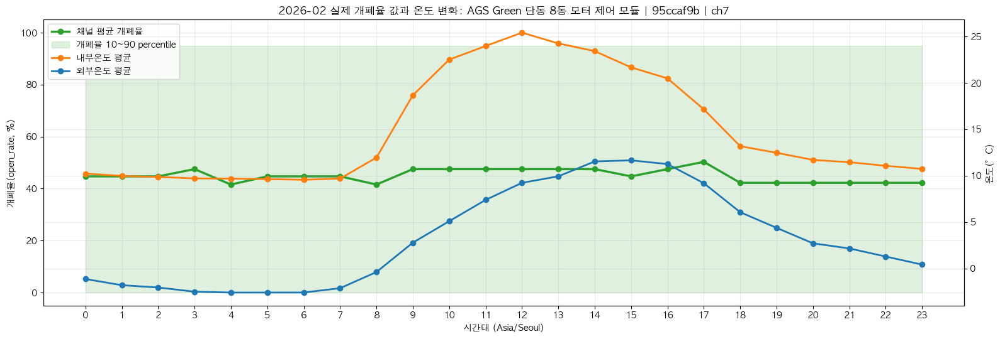

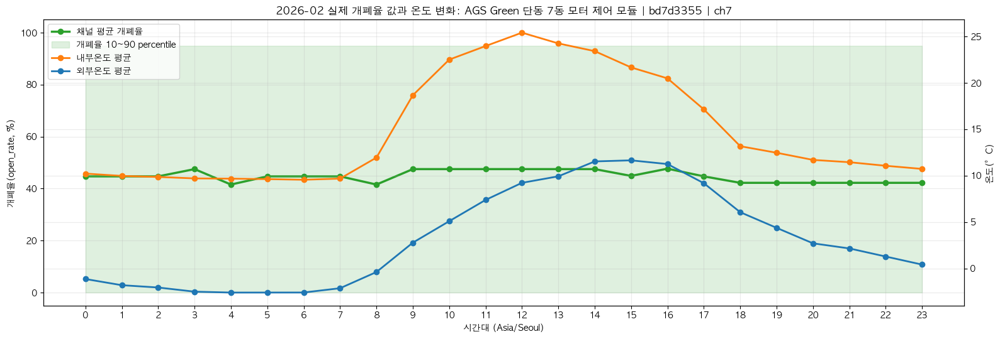

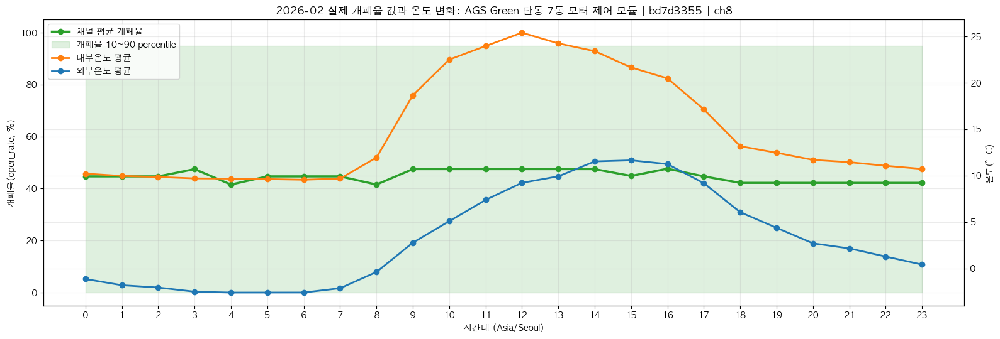

...

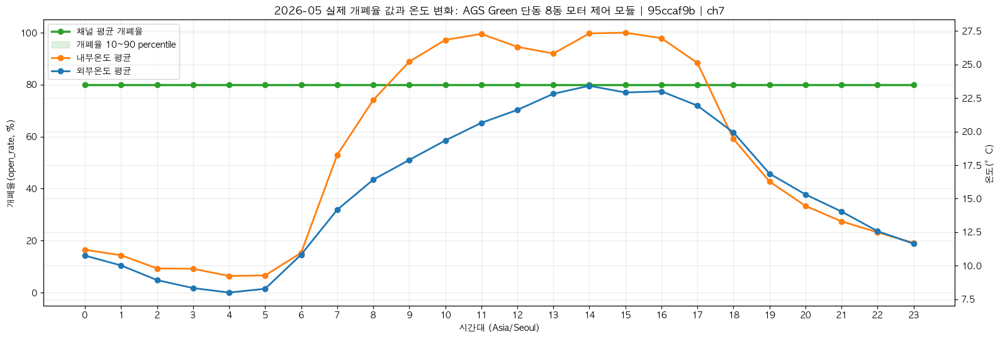

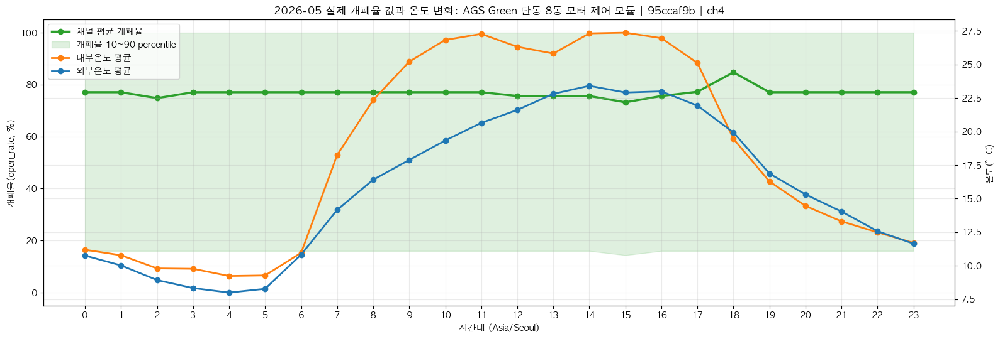

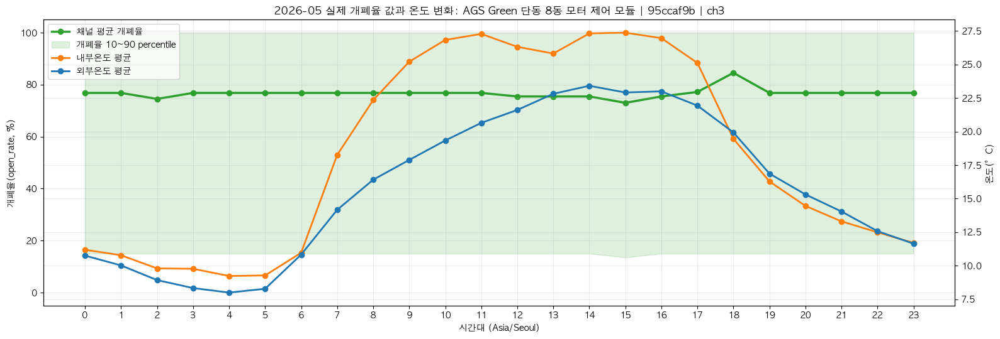

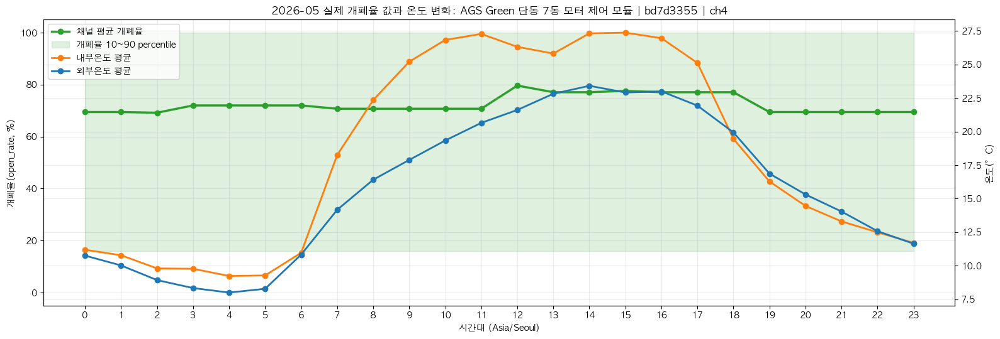

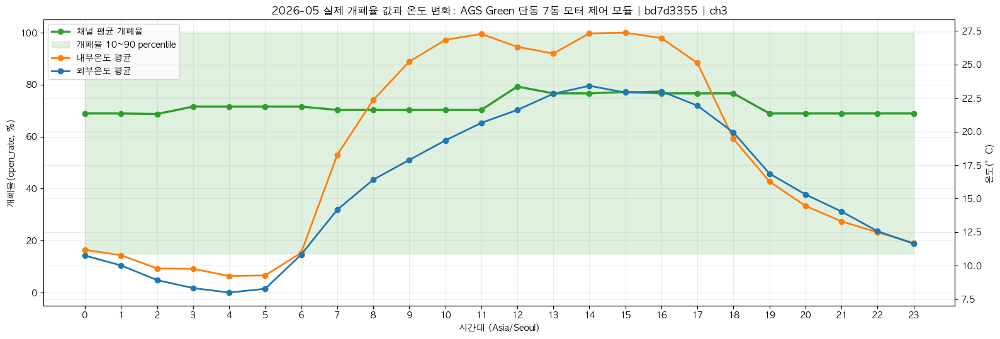

In [23]:
def build_open_rate_hourly_table(records: List[Dict[str, object]]) -> pd.DataFrame:
    hourly_frames = []

    for record in records:
        if record["data_kind"] != "motor_open_rate":
            continue

        frame = record["frame"].copy()
        if frame.empty or "open_rate" not in frame.columns:
            continue

        values = frame[["local_ts", "open_rate", "sensor_label", "source_file"]].copy()
        values["open_rate"] = pd.to_numeric(values["open_rate"], errors="coerce")
        values = values.dropna(subset=["local_ts", "open_rate"]).sort_values("local_ts")
        values = values.drop_duplicates(subset=["local_ts"], keep="last")

        series = values.set_index("local_ts")["open_rate"].resample("1h").median().dropna()
        if series.empty:
            continue

        hourly = pd.DataFrame(
            {
                "local_ts": series.index,
                "open_rate": series.values,
                "sensor_label": record["sensor_label"],
                "source_file": record["relative_path"],
            }
        )
        hourly["date"] = hourly["local_ts"].dt.date
        hourly["hour"] = hourly["local_ts"].dt.hour
        hourly["month"] = hourly["local_ts"].dt.strftime("%Y-%m")
        hourly_frames.append(hourly)

    if not hourly_frames:
        return pd.DataFrame(columns=["local_ts", "open_rate", "sensor_label", "source_file", "date", "hour", "month"])

    return pd.concat(hourly_frames, ignore_index=True).sort_values(["sensor_label", "local_ts"])


def summarize_open_rate_by_month_hour(open_rate_hourly: pd.DataFrame) -> pd.DataFrame:
    if open_rate_hourly.empty:
        return pd.DataFrame(columns=["month", "sensor_label", "hour", "count", "mean", "median", "p10", "p90"])

    return (
        open_rate_hourly[open_rate_hourly["month"].isin(MONTH_ORDER)]
        .groupby(["month", "sensor_label", "hour"])["open_rate"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reset_index()
        .sort_values(["month", "sensor_label", "hour"])
    )


def summarize_open_rate_all_channels_by_month_hour(open_rate_hourly: pd.DataFrame) -> pd.DataFrame:
    if open_rate_hourly.empty:
        return pd.DataFrame(columns=["month", "hour", "count", "mean", "median", "p10", "p90"])

    return (
        open_rate_hourly[open_rate_hourly["month"].isin(MONTH_ORDER)]
        .groupby(["month", "hour"])["open_rate"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reset_index()
        .sort_values(["month", "hour"])
    )


open_rate_hourly = build_open_rate_hourly_table(records)
monthly_open_rate_channel_summary = summarize_open_rate_by_month_hour(open_rate_hourly)
monthly_open_rate_summary = summarize_open_rate_all_channels_by_month_hour(open_rate_hourly)

open_rate_hourly.to_csv(OUTPUT_ROOT / "open_rate_hourly_long.csv", index=False, encoding="utf-8-sig")
monthly_open_rate_channel_summary.to_csv(OUTPUT_ROOT / "monthly_open_rate_by_channel_hour.csv", index=False, encoding="utf-8-sig")
monthly_open_rate_summary.to_csv(OUTPUT_ROOT / "monthly_open_rate_by_hour.csv", index=False, encoding="utf-8-sig")

print(f"1시간 리샘플링 개폐율 행 수: {len(open_rate_hourly):,}")
display(monthly_open_rate_summary)
display(monthly_open_rate_channel_summary.head(40))


def plot_monthly_open_rate_temperature_overlay(month: str) -> None:
    month_open_rate = monthly_open_rate_summary[monthly_open_rate_summary["month"] == month]
    month_temp = monthly_temperature_summary[monthly_temperature_summary["month"] == month]

    if month_open_rate.empty and month_temp.empty:
        display(Markdown(f"`{month}`에는 표시할 개폐율/온도 데이터가 없다."))
        return

    open_rate_profile = month_open_rate.set_index("hour").reindex(range(24))
    temp_pivot = month_temp.pivot(index="hour", columns="scope", values="mean").reindex(range(24)) if not month_temp.empty else pd.DataFrame(index=range(24))

    x = np.arange(24)
    fig, ax1 = plt.subplots(figsize=(16, 5.5))

    if not open_rate_profile.empty:
        mean = open_rate_profile["mean"].to_numpy(dtype=float)
        p10 = open_rate_profile["p10"].to_numpy(dtype=float)
        p90 = open_rate_profile["p90"].to_numpy(dtype=float)
        ax1.plot(x, mean, color="#2ca02c", marker="o", linewidth=2.5, label="전체 채널 평균 개폐율")
        ax1.fill_between(x, p10, p90, color="#2ca02c", alpha=0.15, label="개폐율 10~90 percentile")

    ax1.set_xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
    ax1.set_ylabel("개폐율(open_rate, %)")
    ax1.set_xticks(x)
    ax1.set_ylim(-5, 105)

    ax2 = ax1.twinx()
    if "internal" in temp_pivot.columns:
        ax2.plot(x, temp_pivot["internal"], color="#ff7f0e", marker="o", linewidth=2, label="내부온도 평균")
    if "external" in temp_pivot.columns:
        ax2.plot(x, temp_pivot["external"], color="#1f77b4", marker="o", linewidth=2, label="외부온도 평균")
    ax2.set_ylabel("온도(°C)")

    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
    ax1.set_title(f"{month} 시간대별 실제 개폐율 값과 내부/외부 온도 변화")
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / f"monthly_open_rate_temperature_overlay_{month.replace('-', '_')}.png", dpi=150)
    plt.show()


def plot_monthly_channel_open_rate_temperature_overlay(month: str, max_channels: Optional[int] = None) -> None:
    month_channel_summary = monthly_open_rate_channel_summary[monthly_open_rate_channel_summary["month"] == month]
    month_temp = monthly_temperature_summary[monthly_temperature_summary["month"] == month]

    if month_channel_summary.empty:
        display(Markdown(f"`{month}`에는 채널별 개폐율 데이터가 없다."))
        return

    temp_pivot = month_temp.pivot(index="hour", columns="scope", values="mean").reindex(range(24)) if not month_temp.empty else pd.DataFrame(index=range(24))
    channel_plot_dir = PLOT_ROOT / "monthly_channel_open_rate_overlay" / month.replace("-", "_")
    channel_plot_dir.mkdir(parents=True, exist_ok=True)

    channel_order = (
        month_channel_summary.groupby("sensor_label")["mean"]
        .mean()
        .sort_values(ascending=False)
        .index.tolist()
    )
    if max_channels is not None:
        channel_order = channel_order[:max_channels]

    x = np.arange(24)
    for sensor_label in channel_order:
        channel_profile = (
            month_channel_summary[month_channel_summary["sensor_label"] == sensor_label]
            .set_index("hour")
            .reindex(range(24))
        )

        fig, ax1 = plt.subplots(figsize=(16, 5.5))
        mean = channel_profile["mean"].to_numpy(dtype=float)
        p10 = channel_profile["p10"].to_numpy(dtype=float)
        p90 = channel_profile["p90"].to_numpy(dtype=float)
        ax1.plot(x, mean, color="#2ca02c", marker="o", linewidth=2.5, label="채널 평균 개폐율")
        ax1.fill_between(x, p10, p90, color="#2ca02c", alpha=0.15, label="개폐율 10~90 percentile")
        ax1.set_xlabel(f"시간대 ({ANALYSIS_TIMEZONE})")
        ax1.set_ylabel("개폐율(open_rate, %)")
        ax1.set_xticks(x)
        ax1.set_ylim(-5, 105)

        ax2 = ax1.twinx()
        if "internal" in temp_pivot.columns:
            ax2.plot(x, temp_pivot["internal"], color="#ff7f0e", marker="o", linewidth=2, label="내부온도 평균")
        if "external" in temp_pivot.columns:
            ax2.plot(x, temp_pivot["external"], color="#1f77b4", marker="o", linewidth=2, label="외부온도 평균")
        ax2.set_ylabel("온도(°C)")

        handles1, labels1 = ax1.get_legend_handles_labels()
        handles2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
        ax1.set_title(f"{month} 실제 개폐율 값과 온도 변화: {sensor_label}")
        plt.tight_layout()
        plt.savefig(channel_plot_dir / f"open_rate_temperature_overlay_{safe_filename(sensor_label)}.png", dpi=150)
        plt.show()


for month in MONTH_ORDER:
    plot_monthly_open_rate_temperature_overlay(month)
    plot_monthly_channel_open_rate_temperature_overlay(month)

## 11. 전체 날짜를 x축으로 본 실제 개폐율 변화

앞의 분석은 하루 24시간 패턴이나 월별 평균 패턴을 보기 위해 시간을 접어서 요약했다. 이 방식은 반복 패턴을 이해하기 좋지만, 전체 기간 동안 개폐율이 언제부터 높아졌는지, 특정 날짜에 급격한 변화가 있었는지는 보기 어렵다.

이 절에서는 `2026-02-11`부터 `2026-05-11`까지의 전체 날짜를 x축으로 두고 실제 `open_rate` 값의 변화를 그린다.

그래프는 두 가지 관점으로 작성한다.

- 전체 채널 평균 개폐율과 내부/외부 온도의 장기 변화
- 채널별 실제 개폐율의 장기 변화

해석할 때는 다음을 확인한다.

- 계절이 바뀌면서 평균 개폐율이 점진적으로 높아지는가?
- 특정 날짜 이후 개폐율 baseline이 달라지는가?
- 내부/외부 온도 상승 구간과 개폐율 상승 구간이 같이 움직이는가?
- 일부 채널만 장기간 0 또는 100에 가까운 상태로 유지되는가?

,date,mean,median,p10,p90,channel_count
0,2026-02-11,23.812500,0.0,0.0,95.0,16
1,2026-02-12,28.294271,0.0,0.0,95.0,16
2,2026-02-13,29.377717,0.0,0.0,95.0,16
3,2026-02-14,28.600543,0.0,0.0,95.0,16
4,2026-02-15,26.255208,0.0,0.0,95.0,16
5,2026-02-16,27.324219,0.0,0.0,95.0,16
6,2026-02-17,26.703125,0.0,0.0,95.0,16
7,2026-02-18,26.926630,0.0,0.0,95.0,16
8,2026-02-19,20.630208,0.0,0.0,95.0,16
9,2026-02-20,3.664062,0.0,0.0,9.4,16


,date,sensor_label,mean,median,p10,p90
0,2026-02-11,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,0.000000,0.0,0.0,0.0
16,2026-02-12,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,12.000000,0.0,0.0,59.0
32,2026-02-13,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,12.043478,0.0,0.0,47.0
48,2026-02-14,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,11.478261,0.0,0.0,36.6
64,2026-02-15,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,5.791667,0.0,0.0,27.3
80,2026-02-16,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,13.125000,0.0,0.0,48.5
96,2026-02-17,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,14.750000,0.0,0.0,59.0
112,2026-02-18,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,18.217391,0.0,0.0,74.0
128,2026-02-19,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,16.416667,0.0,0.0,77.1
144,2026-02-20,AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1,9.208333,0.0,0.0,36.0


,date,scope,mean,median,p10,p90
0,2026-02-11,external,2.530000,3.000,-2.960,6.200
1,2026-02-11,internal,14.211667,11.450,7.170,23.610
2,2026-02-12,external,-0.715217,-2.900,-7.100,8.300
3,2026-02-12,internal,12.008696,9.100,5.500,23.875
4,2026-02-13,external,2.847917,1.850,-4.100,11.380
5,2026-02-13,internal,12.768750,10.750,7.600,20.520
6,2026-02-14,external,4.335417,2.375,-1.700,13.315
7,2026-02-14,internal,15.156250,13.150,9.270,26.740
8,2026-02-15,external,4.627083,2.850,-0.455,11.470
9,2026-02-15,internal,14.864583,13.000,11.170,21.150


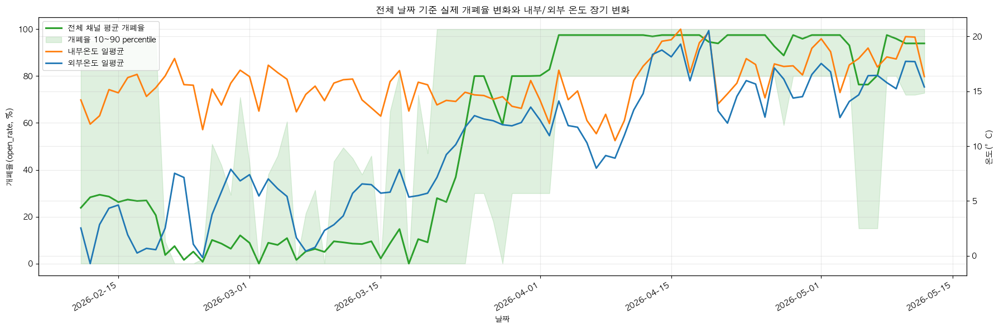

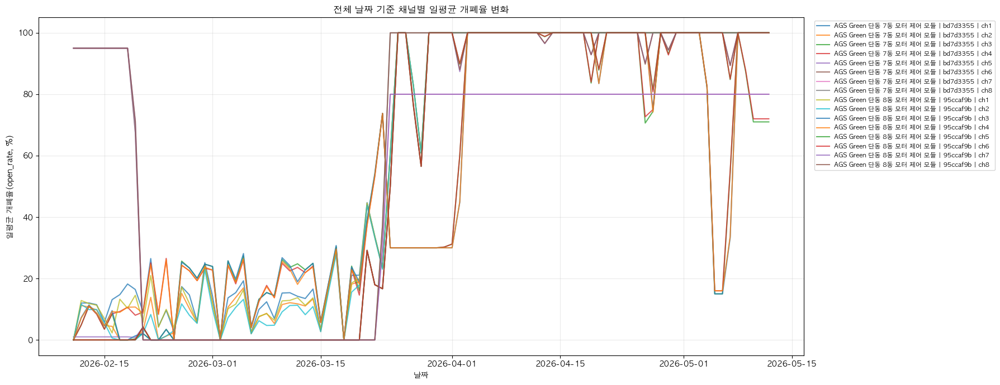

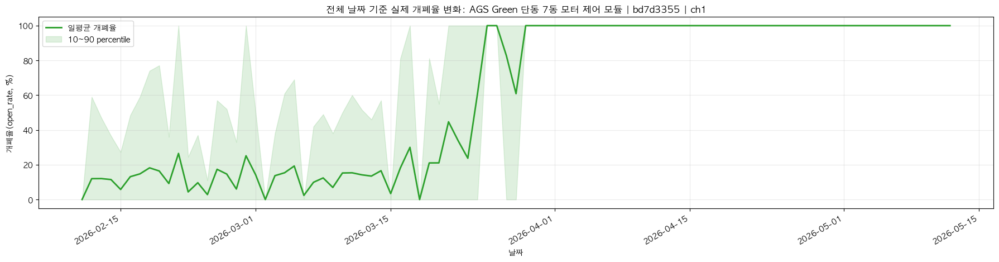

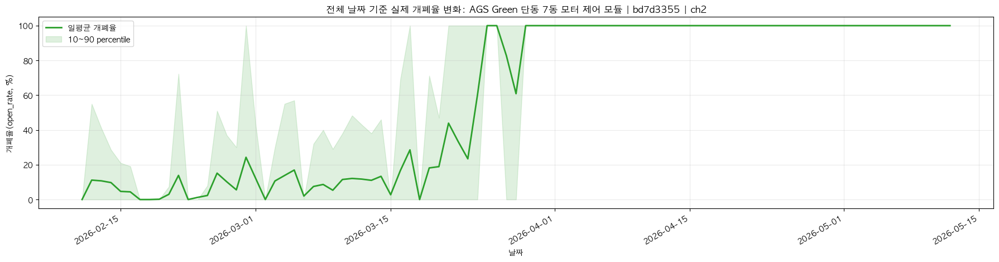

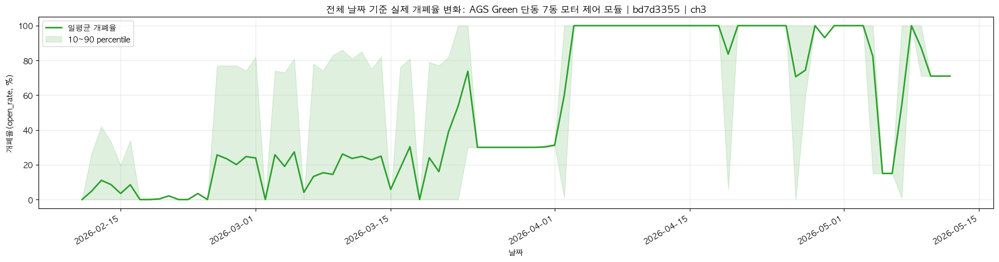

...

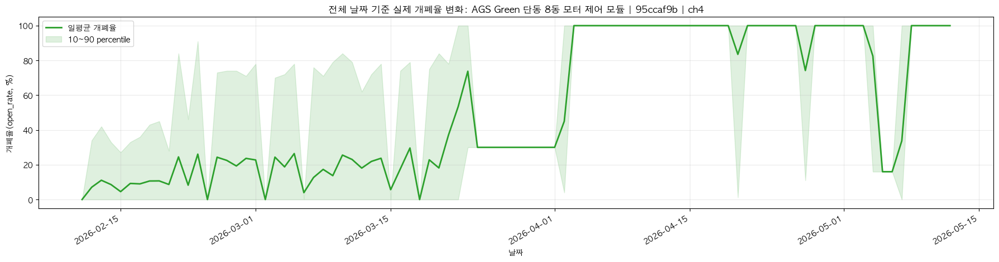

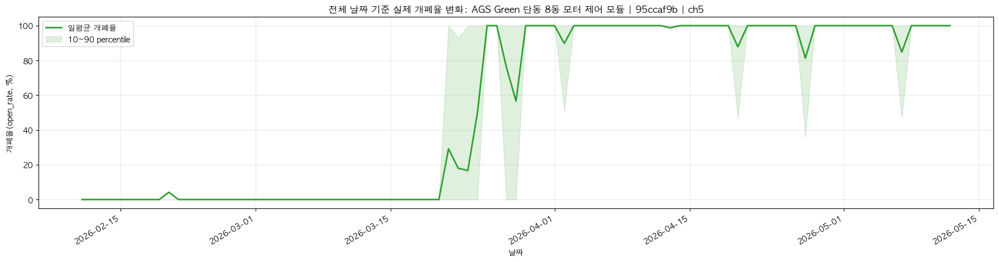

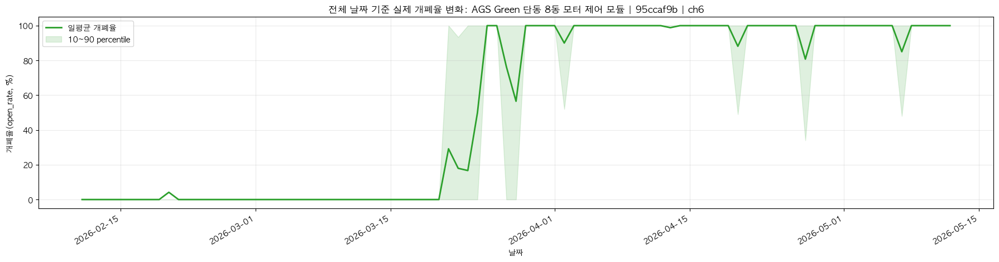

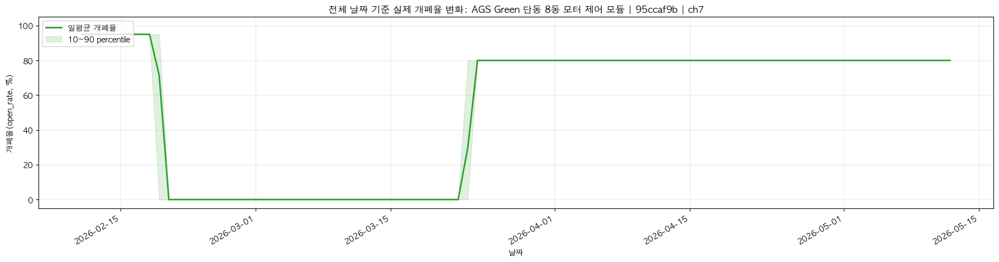

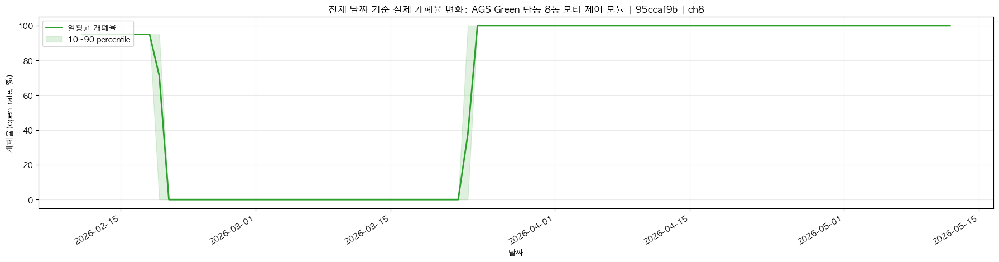

In [24]:
def build_daily_open_rate_summary(open_rate_hourly: pd.DataFrame) -> pd.DataFrame:
    if open_rate_hourly.empty:
        return pd.DataFrame(columns=["date", "mean", "median", "p10", "p90", "channel_count"])

    return (
        open_rate_hourly.groupby("date")
        .agg(
            mean=("open_rate", "mean"),
            median=("open_rate", "median"),
            p10=("open_rate", lambda values: values.quantile(0.10)),
            p90=("open_rate", lambda values: values.quantile(0.90)),
            channel_count=("sensor_label", "nunique"),
        )
        .reset_index()
        .sort_values("date")
    )


def build_daily_channel_open_rate_summary(open_rate_hourly: pd.DataFrame) -> pd.DataFrame:
    if open_rate_hourly.empty:
        return pd.DataFrame(columns=["date", "sensor_label", "mean", "median", "p10", "p90"])

    return (
        open_rate_hourly.groupby(["date", "sensor_label"])["open_rate"]
        .agg(
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reset_index()
        .sort_values(["sensor_label", "date"])
    )


def build_daily_temperature_summary(temperature_hourly: pd.DataFrame) -> pd.DataFrame:
    if temperature_hourly.empty:
        return pd.DataFrame(columns=["date", "scope", "mean", "median", "p10", "p90"])

    return (
        temperature_hourly.groupby(["date", "scope"])["TEMP(기존SDS경로에있던내용)"]
        .agg(
            mean="mean",
            median="median",
            p10=lambda values: values.quantile(0.10),
            p90=lambda values: values.quantile(0.90),
        )
        .reset_index()
        .sort_values(["date", "scope"])
    )


daily_open_rate_summary = build_daily_open_rate_summary(open_rate_hourly)
daily_channel_open_rate_summary = build_daily_channel_open_rate_summary(open_rate_hourly)
daily_temperature_summary = build_daily_temperature_summary(temperature_hourly)

daily_open_rate_summary.to_csv(OUTPUT_ROOT / "daily_open_rate_summary.csv", index=False, encoding="utf-8-sig")
daily_channel_open_rate_summary.to_csv(OUTPUT_ROOT / "daily_open_rate_by_channel.csv", index=False, encoding="utf-8-sig")
daily_temperature_summary.to_csv(OUTPUT_ROOT / "daily_temperature_summary.csv", index=False, encoding="utf-8-sig")

display(daily_open_rate_summary.head(10))
display(daily_channel_open_rate_summary.head(10))
display(daily_temperature_summary.head(10))


def plot_daily_open_rate_temperature_trend(
    daily_open_rate_summary: pd.DataFrame,
    daily_temperature_summary: pd.DataFrame,
) -> None:
    if daily_open_rate_summary.empty and daily_temperature_summary.empty:
        display(Markdown("전체 날짜 x축으로 표시할 개폐율/온도 데이터가 없다."))
        return

    fig, ax1 = plt.subplots(figsize=(18, 6))

    if not daily_open_rate_summary.empty:
        x = pd.to_datetime(daily_open_rate_summary["date"])
        mean = daily_open_rate_summary["mean"].to_numpy(dtype=float)
        p10 = daily_open_rate_summary["p10"].to_numpy(dtype=float)
        p90 = daily_open_rate_summary["p90"].to_numpy(dtype=float)
        ax1.plot(x, mean, color="#2ca02c", linewidth=2.2, label="전체 채널 평균 개폐율")
        ax1.fill_between(x, p10, p90, color="#2ca02c", alpha=0.15, label="개폐율 10~90 percentile")

    ax1.set_xlabel("날짜")
    ax1.set_ylabel("개폐율(open_rate, %)")
    ax1.set_ylim(-5, 105)

    ax2 = ax1.twinx()
    if not daily_temperature_summary.empty:
        temp_pivot = daily_temperature_summary.pivot(index="date", columns="scope", values="mean").sort_index()
        temp_x = pd.to_datetime(temp_pivot.index)
        if "internal" in temp_pivot.columns:
            ax2.plot(temp_x, temp_pivot["internal"], color="#ff7f0e", linewidth=2, label="내부온도 일평균")
        if "external" in temp_pivot.columns:
            ax2.plot(temp_x, temp_pivot["external"], color="#1f77b4", linewidth=2, label="외부온도 일평균")
    ax2.set_ylabel("온도(°C)")

    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
    ax1.set_title("전체 날짜 기준 실제 개폐율 변화와 내부/외부 온도 장기 변화")
    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / "daily_open_rate_temperature_trend.png", dpi=150)
    plt.show()


def plot_daily_channel_open_rate_trends(daily_channel_open_rate_summary: pd.DataFrame) -> None:
    if daily_channel_open_rate_summary.empty:
        display(Markdown("채널별 일별 개폐율 데이터가 없어 그래프를 그리지 않았다."))
        return

    channel_plot_dir = PLOT_ROOT / "daily_channel_open_rate"
    channel_plot_dir.mkdir(parents=True, exist_ok=True)

    plt.figure(figsize=(18, 7))
    for sensor_label, group in daily_channel_open_rate_summary.groupby("sensor_label", sort=True):
        x = pd.to_datetime(group["date"])
        plt.plot(x, group["mean"], linewidth=1.5, alpha=0.75, label=sensor_label)
    plt.xlabel("날짜")
    plt.ylabel("일평균 개폐율(open_rate, %)")
    plt.ylim(-5, 105)
    plt.title("전체 날짜 기준 채널별 일평균 개폐율 변화")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.tight_layout()
    plt.savefig(PLOT_ROOT / "daily_open_rate_by_channel_all.png", dpi=150)
    plt.show()

    for sensor_label, group in daily_channel_open_rate_summary.groupby("sensor_label", sort=True):
        x = pd.to_datetime(group["date"])
        mean = group["mean"].to_numpy(dtype=float)
        p10 = group["p10"].to_numpy(dtype=float)
        p90 = group["p90"].to_numpy(dtype=float)

        fig, ax = plt.subplots(figsize=(18, 4.8))
        ax.plot(x, mean, color="#2ca02c", linewidth=2, label="일평균 개폐율")
        ax.fill_between(x, p10, p90, color="#2ca02c", alpha=0.15, label="10~90 percentile")
        ax.set_xlabel("날짜")
        ax.set_ylabel("개폐율(open_rate, %)")
        ax.set_ylim(-5, 105)
        ax.set_title(f"전체 날짜 기준 실제 개폐율 변화: {sensor_label}")
        ax.legend(loc="upper left")
        fig.autofmt_xdate(rotation=30)
        plt.tight_layout()
        plt.savefig(channel_plot_dir / f"daily_open_rate_{safe_filename(sensor_label)}.png", dpi=150)
        plt.show()


plot_daily_open_rate_temperature_trend(daily_open_rate_summary, daily_temperature_summary)
plot_daily_channel_open_rate_trends(daily_channel_open_rate_summary)

## 12. 해석을 위한 자동 요약

아래 셀은 앞에서 만든 표를 바탕으로 가장 이벤트가 많은 시간대와 온도 차이가 큰 시간대를 자동으로 요약한다.

이번 버전에서는 전체 합산 요약뿐 아니라, **채널별 peak 시간대**와 **월별 peak 시간대**도 함께 정리한다. 이 요약은 최종 결론이라기보다, 사람이 그래프를 읽기 전에 어디를 먼저 봐야 하는지 알려주는 인덱스 역할을 한다.

In [25]:
summary_lines = []

if not motor_hour_summary.empty:
    event_pivot = (
        motor_hour_summary.pivot(index="hour", columns="event_type", values="event_count")
        .reindex(range(24))
        .fillna(0)
    )
    for column in ["open", "close"]:
        if column not in event_pivot.columns:
            event_pivot[column] = 0

    top_open_hour = int(event_pivot["open"].idxmax())
    top_close_hour = int(event_pivot["close"].idxmax())
    summary_lines.append(f"- 전체 합산 기준 열림 이벤트가 가장 많은 시간대는 **{top_open_hour}시**이며, 이벤트 수는 `{int(event_pivot.loc[top_open_hour, 'open'])}`건이다.")
    summary_lines.append(f"- 전체 합산 기준 닫힘 이벤트가 가장 많은 시간대는 **{top_close_hour}시**이며, 이벤트 수는 `{int(event_pivot.loc[top_close_hour, 'close'])}`건이다.")
else:
    summary_lines.append("- 모터 개폐 이벤트를 계산할 수 있는 데이터가 없다.")

if "channel_hour_summary" in globals() and not channel_hour_summary.empty:
    channel_peak = pd.read_csv(OUTPUT_ROOT / "motor_channel_open_close_peak_hours.csv")
    top_open_channel = channel_peak.sort_values("open_event_count", ascending=False).iloc[0]
    top_close_channel = channel_peak.sort_values("close_event_count", ascending=False).iloc[0]
    summary_lines.append(
        f"- 채널별 기준 열림 이벤트가 가장 많은 채널은 **{top_open_channel['sensor_label']}**이며, "
        f"총 `{int(top_open_channel['open_event_count'])}`건, peak 시간대는 `{top_open_channel['top_open_hour']}`시이다."
    )
    summary_lines.append(
        f"- 채널별 기준 닫힘 이벤트가 가장 많은 채널은 **{top_close_channel['sensor_label']}**이며, "
        f"총 `{int(top_close_channel['close_event_count'])}`건, peak 시간대는 `{top_close_channel['top_close_hour']}`시이다."
    )

if not temperature_hour_summary.empty:
    internal = temperature_hour_summary[temperature_hour_summary["scope"] == "internal"]
    external = temperature_hour_summary[temperature_hour_summary["scope"] == "external"]
    if not internal.empty:
        row = internal.loc[internal["mean"].idxmax()]
        summary_lines.append(f"- 내부온도 평균이 가장 높은 시간대는 **{int(row['hour'])}시**이며, 평균은 `{row['mean']:.2f}°C`이다.")
    if not external.empty:
        row = external.loc[external["mean"].idxmax()]
        summary_lines.append(f"- 외부온도 평균이 가장 높은 시간대는 **{int(row['hour'])}시**이며, 평균은 `{row['mean']:.2f}°C`이다.")

if "gap_summary" in globals() and not gap_summary.empty and gap_summary["mean"].notna().any():
    row = gap_summary.loc[gap_summary["mean"].idxmax()]
    summary_lines.append(f"- 내부온도가 외부온도보다 가장 크게 높은 시간대는 **{int(row['hour'])}시**이며, 평균 차이는 `{row['mean']:.2f}°C`이다.")

if "monthly_motor_summary" in globals() and not monthly_motor_summary.empty:
    for month in MONTH_ORDER:
        month_events = monthly_motor_summary[monthly_motor_summary["month"] == month]
        if month_events.empty:
            summary_lines.append(f"- `{month}`에는 모터 개폐 이벤트가 없다.")
            continue
        month_pivot = month_events.pivot_table(index="hour", columns="event_type", values="event_count", aggfunc="sum").reindex(range(24)).fillna(0)
        for column in ["open", "close"]:
            if column not in month_pivot.columns:
                month_pivot[column] = 0
        top_open_hour = int(month_pivot["open"].idxmax()) if month_pivot["open"].sum() > 0 else None
        top_close_hour = int(month_pivot["close"].idxmax()) if month_pivot["close"].sum() > 0 else None
        summary_lines.append(
            f"- `{month}` 월별 합산 기준 열림 peak는 `{top_open_hour}`시, 닫힘 peak는 `{top_close_hour}`시이다 "
            f"(열림 `{int(month_pivot['open'].sum())}`건, 닫힘 `{int(month_pivot['close'].sum())}`건)."
        )

if "monthly_temperature_summary" in globals() and not monthly_temperature_summary.empty:
    for month in MONTH_ORDER:
        month_temp = monthly_temperature_summary[monthly_temperature_summary["month"] == month]
        internal = month_temp[month_temp["scope"] == "internal"]
        external = month_temp[month_temp["scope"] == "external"]
        if not internal.empty:
            row = internal.loc[internal["mean"].idxmax()]
            summary_lines.append(f"- `{month}` 내부온도 평균 최고 시간대는 `{int(row['hour'])}`시이며 `{row['mean']:.2f}°C`이다.")
        if not external.empty:
            row = external.loc[external["mean"].idxmax()]
            summary_lines.append(f"- `{month}` 외부온도 평균 최고 시간대는 `{int(row['hour'])}`시이며 `{row['mean']:.2f}°C`이다.")

summary_path = OUTPUT_ROOT / "analysis_summary.md"
summary_path.write_text("# 모터 개폐 시간대와 온도 변화 자동 요약\n\n" + "\n".join(summary_lines), encoding="utf-8")

display(Markdown("# 자동 요약\n" + "\n".join(summary_lines)))
print(f"요약 저장 위치: {summary_path}")

# 자동 요약
- 전체 합산 기준 열림 이벤트가 가장 많은 시간대는 **10시**이며, 이벤트 수는 `451`건이다.
- 전체 합산 기준 닫힘 이벤트가 가장 많은 시간대는 **16시**이며, 이벤트 수는 `309`건이다.
- 채널별 기준 열림 이벤트가 가장 많은 채널은 **AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1**이며, 총 `237`건, peak 시간대는 `10`시이다.
- 채널별 기준 닫힘 이벤트가 가장 많은 채널은 **AGS Green 단동 7동 모터 제어 모듈 | bd7d3355 | ch1**이며, 총 `178`건, peak 시간대는 `16`시이다.
- 내부온도 평균이 가장 높은 시간대는 **12시**이며, 평균은 `25.70°C`이다.
- 외부온도 평균이 가장 높은 시간대는 **15시**이며, 평균은 `17.79°C`이다.
- 내부온도가 외부온도보다 가장 크게 높은 시간대는 **10시**이며, 평균 차이는 `12.20°C`이다.
- `2026-02` 월별 합산 기준 열림 peak는 `10`시, 닫힘 peak는 `16`시이다 (열림 `481`건, 닫힘 `418`건).
- `2026-03` 월별 합산 기준 열림 peak는 `10`시, 닫힘 peak는 `17`시이다 (열림 `882`건, 닫힘 `690`건).
- `2026-04` 월별 합산 기준 열림 peak는 `18`시, 닫힘 peak는 `16`시이다 (열림 `189`건, 닫힘 `185`건).
- `2026-05` 월별 합산 기준 열림 peak는 `18`시, 닫힘 peak는 `18`시이다 (열림 `44`건, 닫힘 `49`건).
- `2026-02` 내부온도 평균 최고 시간대는 `12`시이며 `25.41°C`이다.
- `2026-02` 외부온도 평균 최고 시간대는 `15`시이며 `11.65°C`이다.
- `2026-03` 내부온도 평균 최고 시간대는 `12`시이며 `25.66°C`이다.
- `2026-03` 외부온도 평균 최고 시간대는 `15`시이며 `15.32°C`이다.
- `2026-04` 내부온도 평균 최고 시간대는 `11`시이며 `25.87°C`이다.
- `2026-04` 외부온도 평균 최고 시간대는 `15`시이며 `22.26°C`이다.
- `2026-05` 내부온도 평균 최고 시간대는 `15`시이며 `27.38°C`이다.
- `2026-05` 외부온도 평균 최고 시간대는 `14`시이며 `23.41°C`이다.

요약 저장 위치: /Users/jeong-won-il/workspace/SDF/train/data_inspect/output/motor_temperature_daily_pattern_260211-260511/analysis_summary.md


## 13. 결과 파일

이 노트북을 실행하면 다음 파일이 생성된다.

### 전체 기간 분석

- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/motor_open_close_events.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/motor_open_close_events_by_hour.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/motor_open_close_events_by_channel_hour.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/motor_channel_open_close_peak_hours.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/temperature_raw_long.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/temperature_hourly_long.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/temperature_hourly_profile.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/temperature_internal_external_gap_hourly.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/temperature_internal_external_gap_by_hour.csv`

### 월별 분석

- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/monthly_motor_open_close_events_by_hour.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/monthly_motor_open_close_events_by_channel_hour.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/monthly_motor_channel_open_close_peak_hours.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/monthly_temperature_hourly_profile.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/monthly_temperature_internal_external_gap_by_hour.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/open_rate_hourly_long.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/monthly_open_rate_by_hour.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/monthly_open_rate_by_channel_hour.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/daily_open_rate_summary.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/daily_open_rate_by_channel.csv`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/daily_temperature_summary.csv`

### 요약과 그래프

- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/analysis_summary.md`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/plots/*.png`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/plots/channel_overlay/*.png`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/plots/monthly_open_rate_temperature_overlay_*.png`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/plots/monthly_channel_open_rate_overlay/**/*.png`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/plots/daily_open_rate_temperature_trend.png`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/plots/daily_open_rate_by_channel_all.png`
- `data_inspect/output/motor_temperature_daily_pattern_260211-260511/plots/daily_channel_open_rate/*.png`

## 해석 시 주의사항

- 이 분석은 모터 명령 로그가 아니라 `open_rate` 관측값 변화로 개폐 이벤트를 추정한다.
- timestamp는 UTC로 파싱한 뒤 한국 시간으로 변환해 24시간 패턴을 계산한다.
- 이벤트 수가 많다는 것은 해당 시간대에 제어 변화가 많이 관측되었다는 뜻이며, 실제 제어 명령 횟수와 완전히 같지 않을 수 있다.
- 채널별 그래프는 특정 채널의 동작 패턴을 더 잘 보여주지만, 채널의 실제 물리적 위치와 역할은 별도 메타데이터와 함께 해석해야 한다.
- 월별 분석은 계절 변화의 영향을 보기 위한 것이며, 2월과 5월은 분석 기간이 한 달 전체가 아니므로 월간 이벤트 수 자체를 직접 비교할 때 주의해야 한다.
- 내부/외부 온도 비교는 같은 시간대에 관측 가능한 데이터가 있는 경우에만 계산된다.
- 더 엄밀한 원인 분석을 위해서는 일사량, 강우, 풍속, 제어 정책, 시설별 위치, 채널별 역할을 함께 검토하는 것이 좋다.